In [1]:
import ipdb
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import pandas as pd
import cartopy
import cartopy.crs as ccrs
from endgame import hist2d
from eod import msg
import datetime
import glob
from shared.utils import u_style, u_stats
from shared.LMCS import glob_util
from shared.paths import load_paths
from scipy.stats import linregress
import os

from scipy.stats import binned_statistic_2d
from scipy import stats
import pickle as pkl
from scipy.stats import gaussian_kde, linregress
import importlib

%matplotlib inline

In [2]:
REGIONS = glob_util.REGIONS
style = glob_util.REGION_STYLE


paths = load_paths()
ROOT = paths.datasets["obs_mcs_5000km2_tables_ERA"]
print("Using ROOT:", ROOT)
YEARS = range(2000, 2020)


region_groups = {
    "GPlains": "midlat",
    "Eur": "midlat",
    "china": "midlat",
    "SAf": "midlat",
    "subSA": "midlat",

    "tropSA": "tropics",
    "WAf": "tropics",
    "CAf": "tropics",
    "EAf": "tropics",
    "australia": "tropics",
    "india": "tropics",

    "Atl": "ocean",
    "Pcf": "ocean",
    "InO": "ocean"
}

Using ROOT: /prj/global_water/MCS_5000km2_tables_v3/ERA5_storm_timeseries


In [47]:
# old_obs = pd.read_csv('/prj/global_water/other/CP4/MCS_files_CP4_CLOVER/CLOVER_mcs_tables/obs_bulk_-50_5000km2_GPM_passiveMW_5-18N_17W13E_ERA0.7_15kprecip_hourly.csv')
# cp4_hist = pd.read_csv('/prj/global_water/other/CP4/MCS_files_CP4_CLOVER/CLOVER_mcs_tables/CP4hist_bulk_-50_5000km2_5-25N_12W15E_15kprecip_hourly.csv')
# cp4_fut = pd.read_csv('/prj/global_water/other/CP4/MCS_files_CP4_CLOVER/CLOVER_mcs_tables/CP4fut_bulk_-50_5000km2_5-25N_12W15E_15kprecip_hourly.csv')

In [4]:
fpath = '/prj/global_water/CP_models/MCS_files/bulk_saves/'

In [5]:
def create_dic(dic):
    
    tt = np.array(dic['tmin'])
    mask = np.where(tt<=-50)
    
    pp = np.array(dic['pmax'])[mask]
    sh = np.array(dic['shear'])[mask] #np.array(dic['shear']) * (-1)
    umin = np.array(dic['u650'])[mask]
    umax = np.array(dic['u925'])[mask]
    qq = np.array(dic['q925'])[mask]
    qup = np.array(dic['q650'])[mask]
    tup = np.array(dic['t650'])[mask]
    tlow = np.array(dic['t925'])[mask]
    tt = np.array(dic['tmin'])[mask]
    ttm = np.array(dic['tmean'])[mask]
    month = np.array(dic['month'])[mask]
    hour = np.array(dic['hour'])[mask]
    year = np.array(dic['year'])[mask]
    area = np.array(dic['area'])[mask]
    lat = np.array(dic['clat'])[mask]
    lon = np.array(dic['clon'])[mask]
    tcwv = np.array(dic['tcwv'])[mask]
    rh = np.array(dic['rh925'])[mask]

    obs_pcp = {
        'prcp' : pp,
        #'u650' : umin,
        #'u925' : umax,
        'q925' : qq*1000,
        #'q650' : qup*1000,
        't925' : tlow-273.15,
        #'t650' : tup-273.15,
        'shear' : sh*-1,
        #'month' : month,    
        'hour' : hour,
        #'year' : year,
        'area' : (area)*(5**2),
        'tmin' : tt,
        #'rh' : rh,
        #'tmean' : ttm,
        #'theta' : theta,
        'lat' : lat,
        'lon' : lon,
        'tcwv' : tcwv,
    } 
    
    obs = pd.DataFrame(obs_pcp)
    return obs

In [6]:
def create_dic_model(dic):
    
    pp = np.array(dic['pmax'])
    sh = np.array(dic['shearmin']) #np.array(dic['shear']) * (-1)
    umin = np.array(dic['umin_mid'])
    umax = np.array(dic['umax_srfc'])
    qq = np.array(dic['qmax']) #+ 0.5
    tup = np.array(dic['tmidmax'])
    tcwv = np.array(dic['tcwv'])
    tgrad = np.array(dic['tgrad'])
    tbox = np.array(dic['tdiff'])
    tt = np.array(dic['tmin'])
    ttm = np.array(dic['tmean'])
    month = np.array(dic['month'])
    tsrfc = np.array(dic['tsrfcmax']) #+ 3
    area = np.array(dic['area'])
    lat = np.array(dic['clat'])
    lon = np.array(dic['clon'])


    obs_pcp = {
        'prcp' : pp,
        #'u650' : umin,
        #'u925' : umax,
        'q925' : qq,
        't925' : tsrfc,
        'tcwv' : tcwv,
        'shear' : sh*-1,
        #'month' : month,
        'area' : (area)*(4.4**2),
        'tmin' : tt,
        #'tmean' : ttm,
        'lat' : lat,
        'lon' : lon,
    } 

    
    obs = pd.DataFrame(obs_pcp)
    return obs

In [7]:
ttag = 'hourly'
if ttag=='hourly':
    rres = 'means'
else:
    rres = '0.7deg'
cp4_histf = ('modelhist', fpath + 'bulk_-50_5000km2_CP4'+rres+'_'+ttag+'_SAHEL_15kmprecip_WA_5-20N_-50C_TCWV_hist_*.p')
cp4_futf = ('modelfut' , fpath + 'bulk_-50_5000km2_CP4'+rres+'_'+ttag+'_SAHEL_15kmprecip_WA_5-20N_-50C_TCWV_fut_*.p')
gpmf = ('obs' , fpath + 'bulk_-50_5000km2_GPM_5-26N_16W17E_p15_ERA0.7_TCWV_'+ttag+'_*.p')
dlist = [cp4_histf,cp4_futf,gpmf]

In [8]:
for d in dlist:
    
    #ipdb.set_trace()
    ds = glob.glob(d[1])
    
    
    for ids, dss in enumerate(ds):
        data = pkl.load( open (dss, 'rb'))
        #data.update(dat)
        
        if 'model' in d[0]:
            if d[0] == 'modelhist':
                histf = create_dic_model(data)
                if ids > 0:
                    cp4_hist = pd.concat([cp4_hist, histf])
                else:
                    cp4_hist = histf    
            else:
                futf = create_dic_model(data)
                if ids > 0:
                    cp4_fut = pd.concat([cp4_fut, futf])
                else:
                    cp4_fut = futf
        if 'obs' in d[0]:
            if d[0] == 'obsm':
                obs_gpmc_m = create_dic(data)
                if ids > 0:
                    old_obs = pd.concat([old_obs, obs_gpmc_m])
                else:
                    old_obs = obs_gpmc_m
            else:
                obs_gpmf_h = create_dic(data)
                if ids > 0:
                    old_obs = pd.concat([old_obs, obs_gpmf_h])
                else:
                    old_obs = obs_gpmf_h
                    

        del data

/tmp/ipykernel_3300024/152691235.py:8: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  data = pkl.load( open (dss, 'rb'))


In [9]:
obs = old_obs[old_obs['prcp']>=3]
cp4h = cp4_hist[(cp4_hist['area']>=5000) & (cp4_hist['prcp']>=3)]
cp4f = cp4_fut[(cp4_fut['area']>=5000) & (cp4_fut['prcp']>=3)]

In [10]:
np.min(old_obs['lat'])

5.163266295264673

In [11]:
df_all = pd.read_parquet(paths.shear_data + '/reduced_shear_study_data.parquet')

In [12]:
df_storm = df_all[(df_all["rel_hour"] == 0) & (df_all["precipitation_max"] >= 3)].copy() # &
df_env = df_all[(df_all["rel_hour"] == -3) & (df_all["precipitation_max"] >= 3)].copy() # &

print(len(df_all), "storms before filtering")
print(len(df_env), "storms after filtering")
df_storm = df_storm.dropna(subset=["precipitation_p99","precipitation_max", "area","area50", "area60", "precipitation_area1mm", "precipitation_area8mm", "tcwv", "shear100_650", "q925", "cape", "iwv_925_750"])
df_env = df_env.dropna(subset=["precipitation_p99","precipitation_max", "area","area50", "area60", "precipitation_area1mm", "precipitation_area8mm", "tcwv", "shear100_650", "q925", "cape", "iwv_925_750"])

df_storm['q925'] = df_storm['q925'] * 1000
df_env['q925'] = df_env['q925'] * 1000

19425083 storms before filtering
1829592 storms after filtering


In [34]:
name_mapper = {'precipitation_max' : 'prcp', 'q925' : 'q925', 'q850' : 'q850', 't925' : 't925', 'tcwv' : 'tcwv', 'ushear100_650' : 'shear', "area" : "area40", 'area50' : 'area',
               'tmin' : 'tmin', 'tmean' : 'tmean', 'hour' : 'lt_hour', 'u650': 'u650', '70area' : 'area70', 'q650' : 'q650', 'rh925': 'rh925', 'rh650' : 'rh650', 'cape':'cape'}

smaller_reg = df_env.rename(columns=name_mapper)

In [14]:
smaller_reg.keys()

Index(['storm_id', 'rel_hour', 'tcwv', 'shear100_650', 'u650', 'shear', 'q925',
       'cape', 'date', 'month', 'lt_hour', 'minute', 'year', 'day', 'area',
       'area70', 'area60', 'area', 'minlon', 'minlat', 'maxlon', 'maxlat',
       'clon', 'clat', 'tminlon', 'tminlat', 'tmin', 'tmean', 'tp1', 'tp99',
       'stormID', 'shape_complexity', 'major_axis_km', 'minor_axis_km',
       'aspect_ratio', 'precipitation_mean', 'prcp', 'precipitation_p80',
       'precipitation_p90', 'precipitation_p95', 'precipitation_p99',
       'precipitation_area1mm', 'precipitation_area3mm',
       'precipitation_area8mm', 'region', 'storm_utc_time', 'storm_lt_time',
       'storm_utc_hour', 'storm_lt_hour', 'lsm', 'topographic_complexity',
       'topographic_complexity_sdfor_slor', 'rh650', 'iwv_925_750',
       'qmean_925_750'],
      dtype='str')

In [16]:
print('glob', smaller_reg[smaller_reg['region']=='WAf']['area'].min())
print('cp4h', cp4h['area'].min()) ### CP4 is actually starting 1000km2
print('cp4f', cp4f['area'].min())
print('obs', obs['area'].min())

glob area    5000.007812
area     112.104729
dtype: float64
cp4h 5014.240000000001
cp4f 5014.240000000001
obs 5000.0


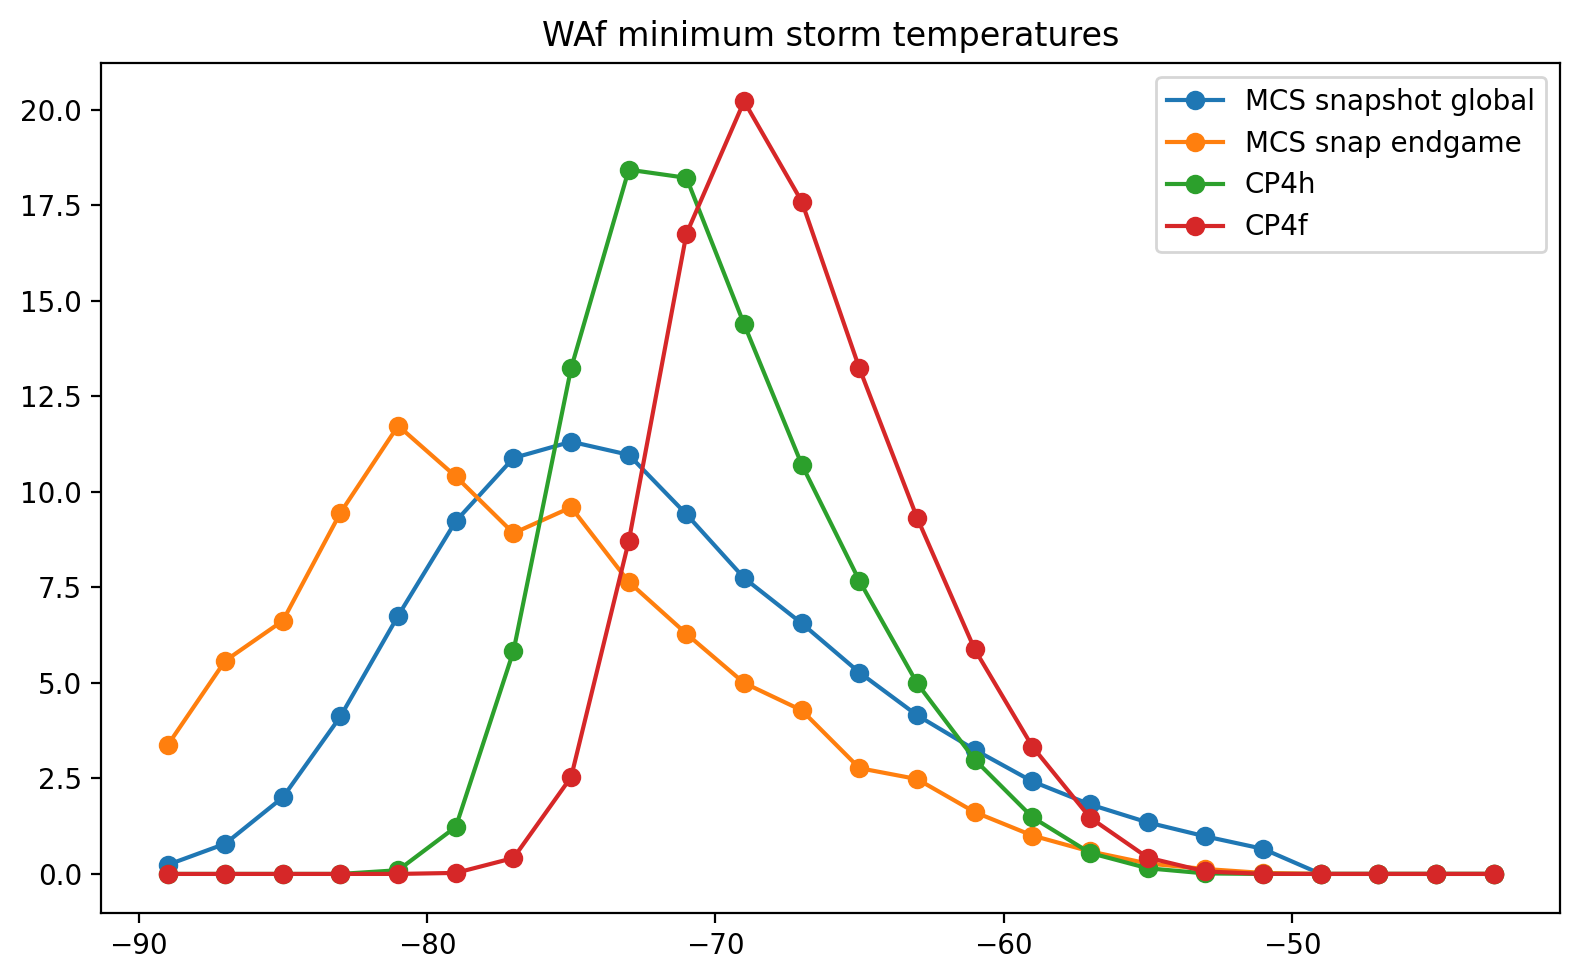

In [17]:
f= plt.figure(figsize=(8,5), dpi=200)

regs = 'WAf'

ax = f.add_subplot(111)

pick = smaller_reg[smaller_reg['region']==regs]

hist_freq, hist_count, bin_edge = u_stats.histo_frequency(pick['tmin'], bins=np.arange(-90,-40,2))
mid_bin = bin_edge[0:-1] + (bin_edge[1::]-bin_edge[0:-1])/2
ax.plot(mid_bin,hist_freq, marker='o', label='MCS snapshot global')
ax.set_title(regs+' minimum storm temperatures')

subpick = pick[pick['prcp']>=10]
hist_freq, hist_count, bin_edge = u_stats.histo_frequency(obs['tmin'], bins=np.arange(-90,-40,2))
mid_bin = bin_edge[0:-1] + (bin_edge[1::]-bin_edge[0:-1])/2
ax.plot(mid_bin,hist_freq, marker='o', label='MCS snap endgame')

hist_freq, hist_count, bin_edge = u_stats.histo_frequency(cp4h['tmin'], bins=np.arange(-90,-40,2))
mid_bin = bin_edge[0:-1] + (bin_edge[1::]-bin_edge[0:-1])/2
ax.plot(mid_bin,hist_freq, marker='o', label='CP4h')

hist_freq, hist_count, bin_edge = u_stats.histo_frequency(cp4f['tmin'], bins=np.arange(-90,-40,2))
mid_bin = bin_edge[0:-1] + (bin_edge[1::]-bin_edge[0:-1])/2
ax.plot(mid_bin,hist_freq, marker='o', label='CP4f')
#f.savefig('/home/ck/Desktop/lmcs/seasonal_cycle_storm_mint_dist.jpg')
plt.legend()
plt.tight_layout()
#f.savefig(cnst.FIGS+'/LMCS/trackVSsnapshot/australia_tmin_pmaxgt2mm.jpg')

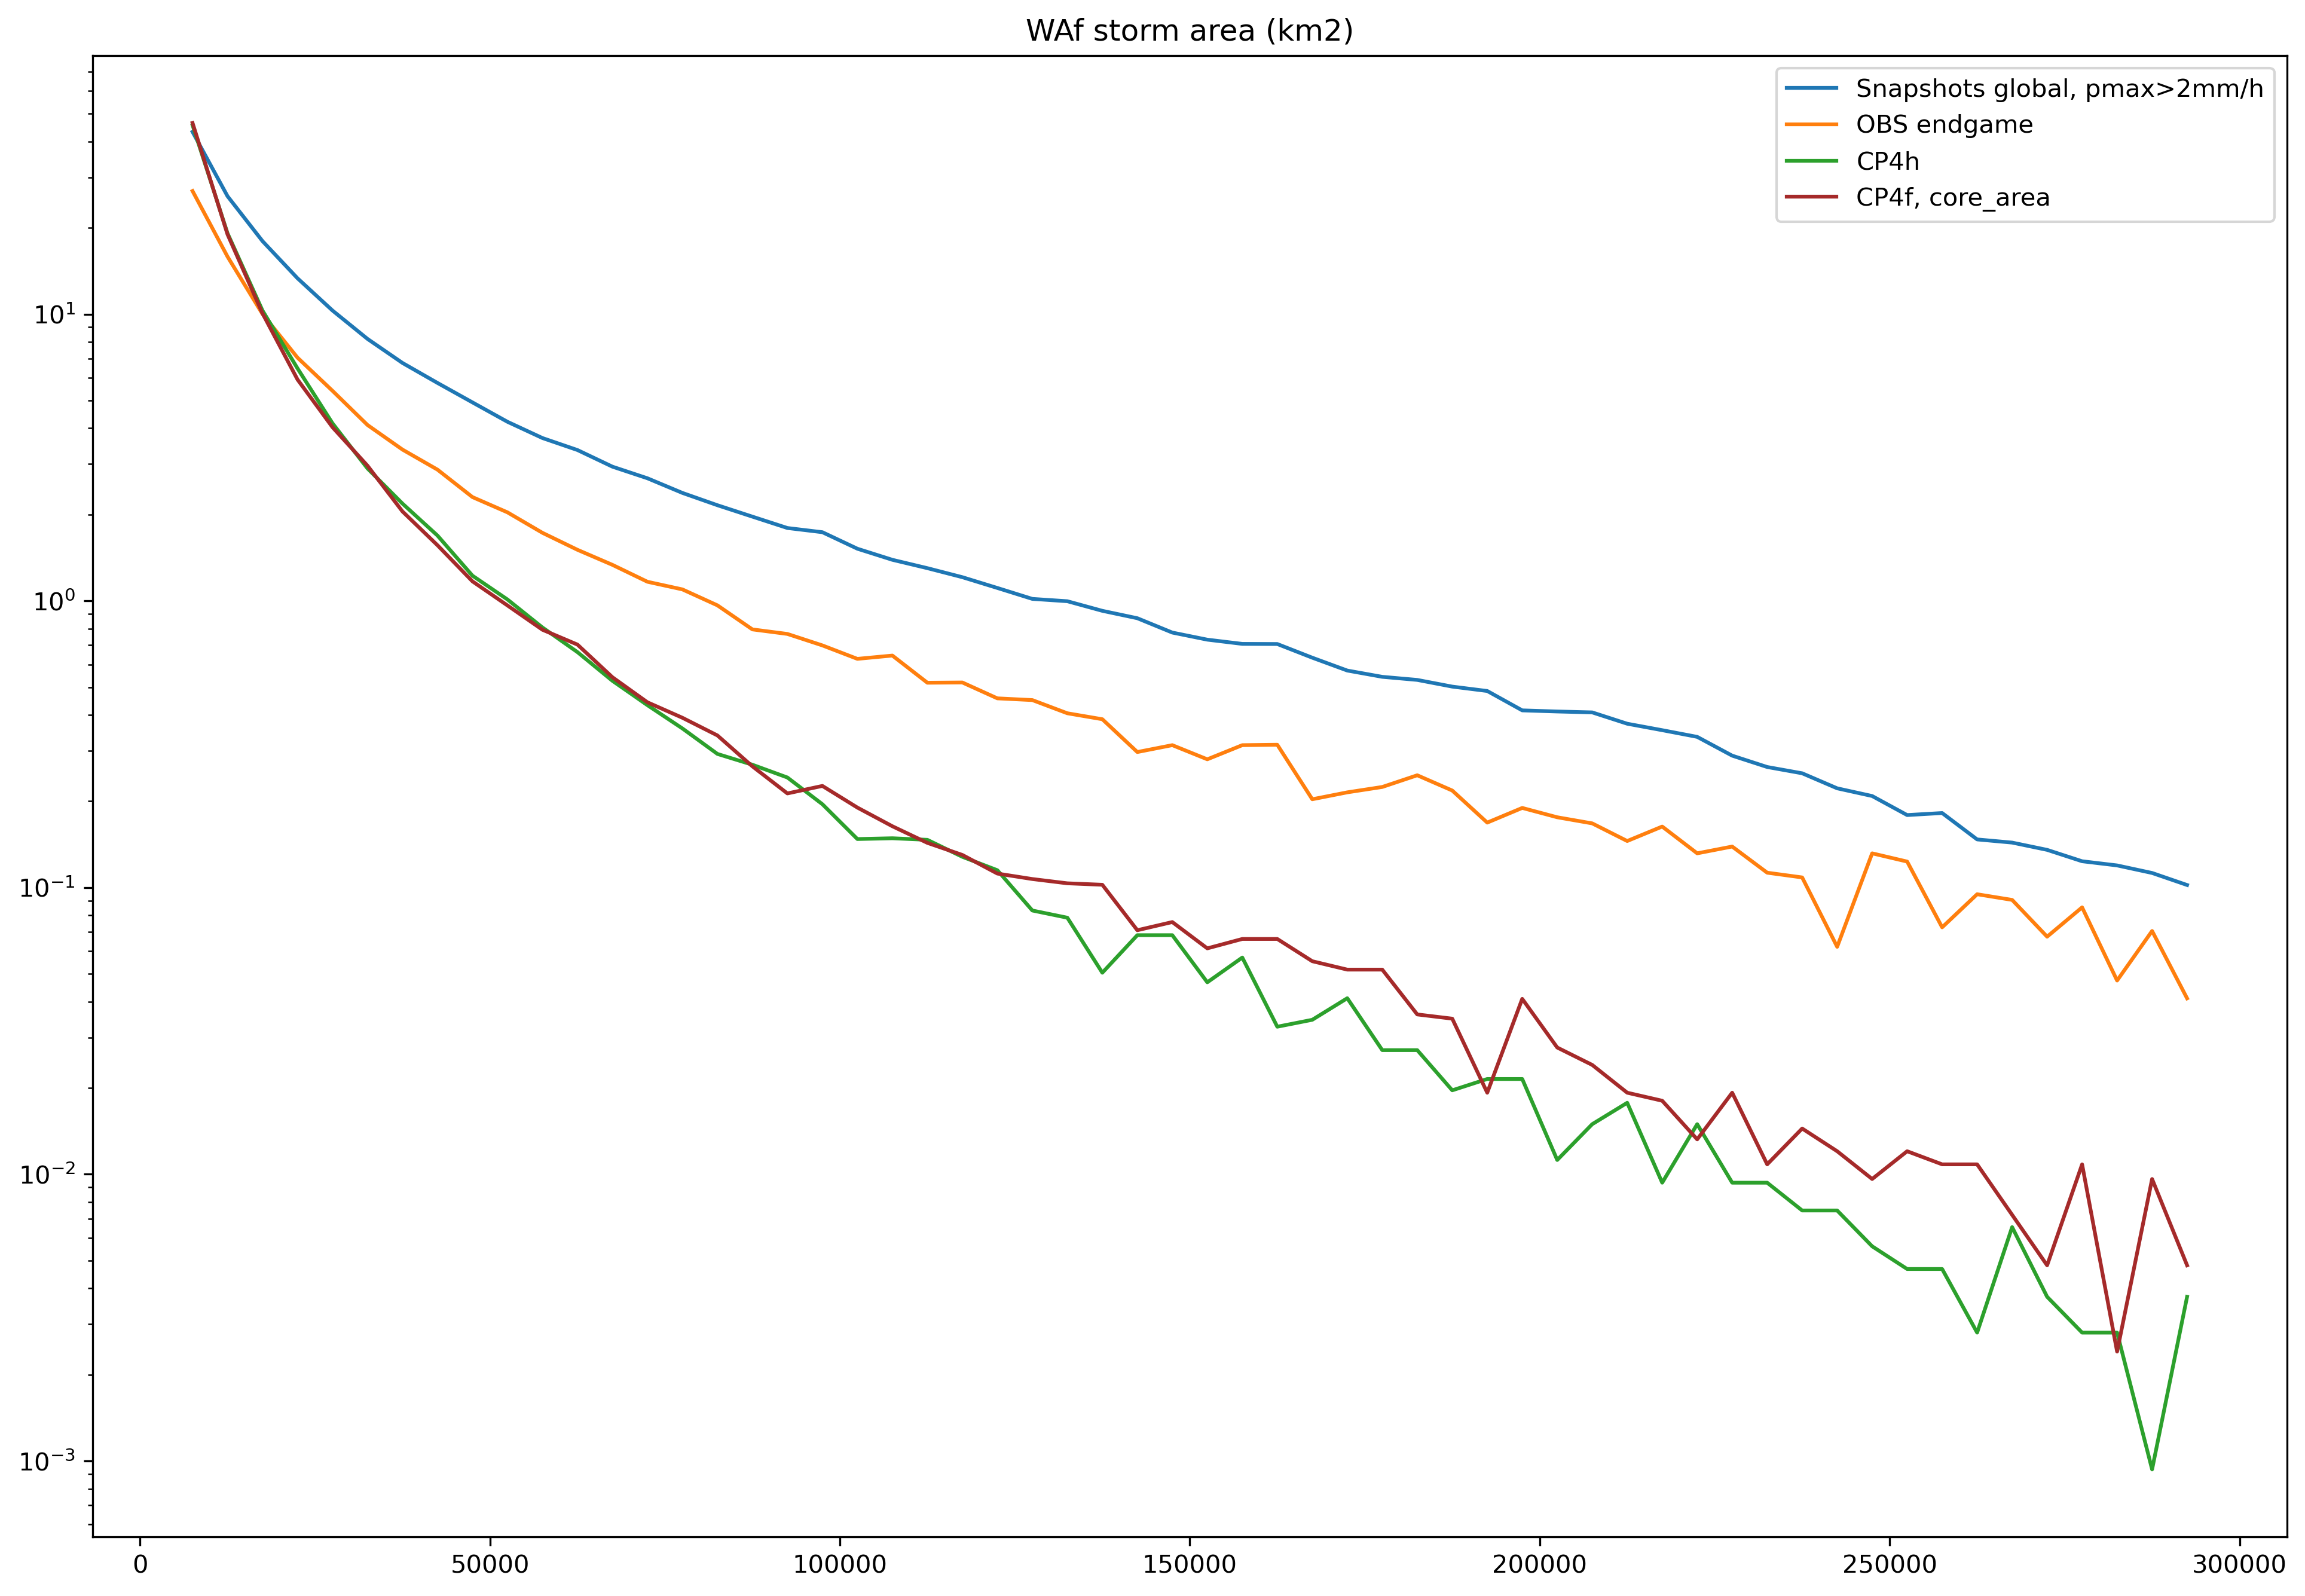

In [18]:
f= plt.figure(figsize=(13,9), dpi=300)

regs = 'WAf'

ax = f.add_subplot(111)

pick = smaller_reg[smaller_reg['region']==regs]

hist_freq, hist_count, bin_edge = u_stats.histo_frequency(pick['area'], bins=np.arange(5000,300000,5000))
mid_bin = bin_edge[0:-1] + (bin_edge[1::]-bin_edge[0:-1])/2
ax.plot(mid_bin,hist_freq, label='Snapshots global, pmax>2mm/h')
ax.set_title(regs+' storm area (km2)')

hist_freq, hist_count, bin_edge = u_stats.histo_frequency(obs['area'], bins=np.arange(5000,300000,5000))
mid_bin = bin_edge[0:-1] + (bin_edge[1::]-bin_edge[0:-1])/2
ax.plot(mid_bin,hist_freq, label='OBS endgame')

hist_freq, hist_count, bin_edge = u_stats.histo_frequency(cp4h['area'], bins=np.arange(5000,300000,5000))
mid_bin = bin_edge[0:-1] + (bin_edge[1::]-bin_edge[0:-1])/2
ax.plot(mid_bin,hist_freq, label='CP4h')

hist_freq, hist_count, bin_edge = u_stats.histo_frequency(cp4f['area'], bins=np.arange(5000,300000,5000))
mid_bin = bin_edge[0:-1] + (bin_edge[1::]-bin_edge[0:-1])/2
ax.plot(mid_bin,hist_freq, label='CP4f, core_area', color='brown')
ax.set_yscale('log')
plt.legend()
#f.savefig('/home/ck/Desktop/lmcs/seasonal_cycle_storm_mint_dist.jpg')
plt.tight_layout()
#f.savefig(cnst.FIGS+'/LMCS/trackVSsnapshot/australia_trackVSsnapshot_area_histo.jpg')

slopes: [0.27360948 0.46727195 0.39186497 0.49160628 0.46508834 0.5408522
 0.56458426 0.45319565 0.47629901 0.35894853 0.58269297]
pvals: [8.24205324e-04 2.33914503e-03 5.14901307e-05 6.19832284e-06
 1.24355176e-08 5.82228328e-06 3.47580649e-05 1.24697748e-06
 4.57838336e-08 2.56525736e-03 5.28618943e-05]
slopes: [0.12758154 0.12619412 0.2107609  0.17760815 0.27024817 0.63131551
 0.45862689 0.68190564 0.34532578 0.5361166  0.84312227]
pvals: [4.77599387e-01 1.28782872e-01 1.44502543e-01 1.49996105e-01
 2.58203880e-02 8.68787472e-05 1.79684619e-03 8.99778248e-06
 1.18487843e-03 7.28585968e-05 1.46043490e-03]
slopes: [-0.01682722  0.12099622  0.34374573  0.09773842  0.26430605  0.44815094
  0.50912397  0.94076316  0.91146626  0.94393935  1.05675618]
pvals: [6.68277948e-01 2.00196339e-01 7.66781394e-03 2.48348441e-01
 3.05249271e-03 3.55583942e-06 2.43337846e-07 1.00079090e-06
 3.72736211e-10 5.20826084e-09 4.19158587e-07]
slopes: [       nan        nan 0.27866947 0.17900821 0.11693668 0.

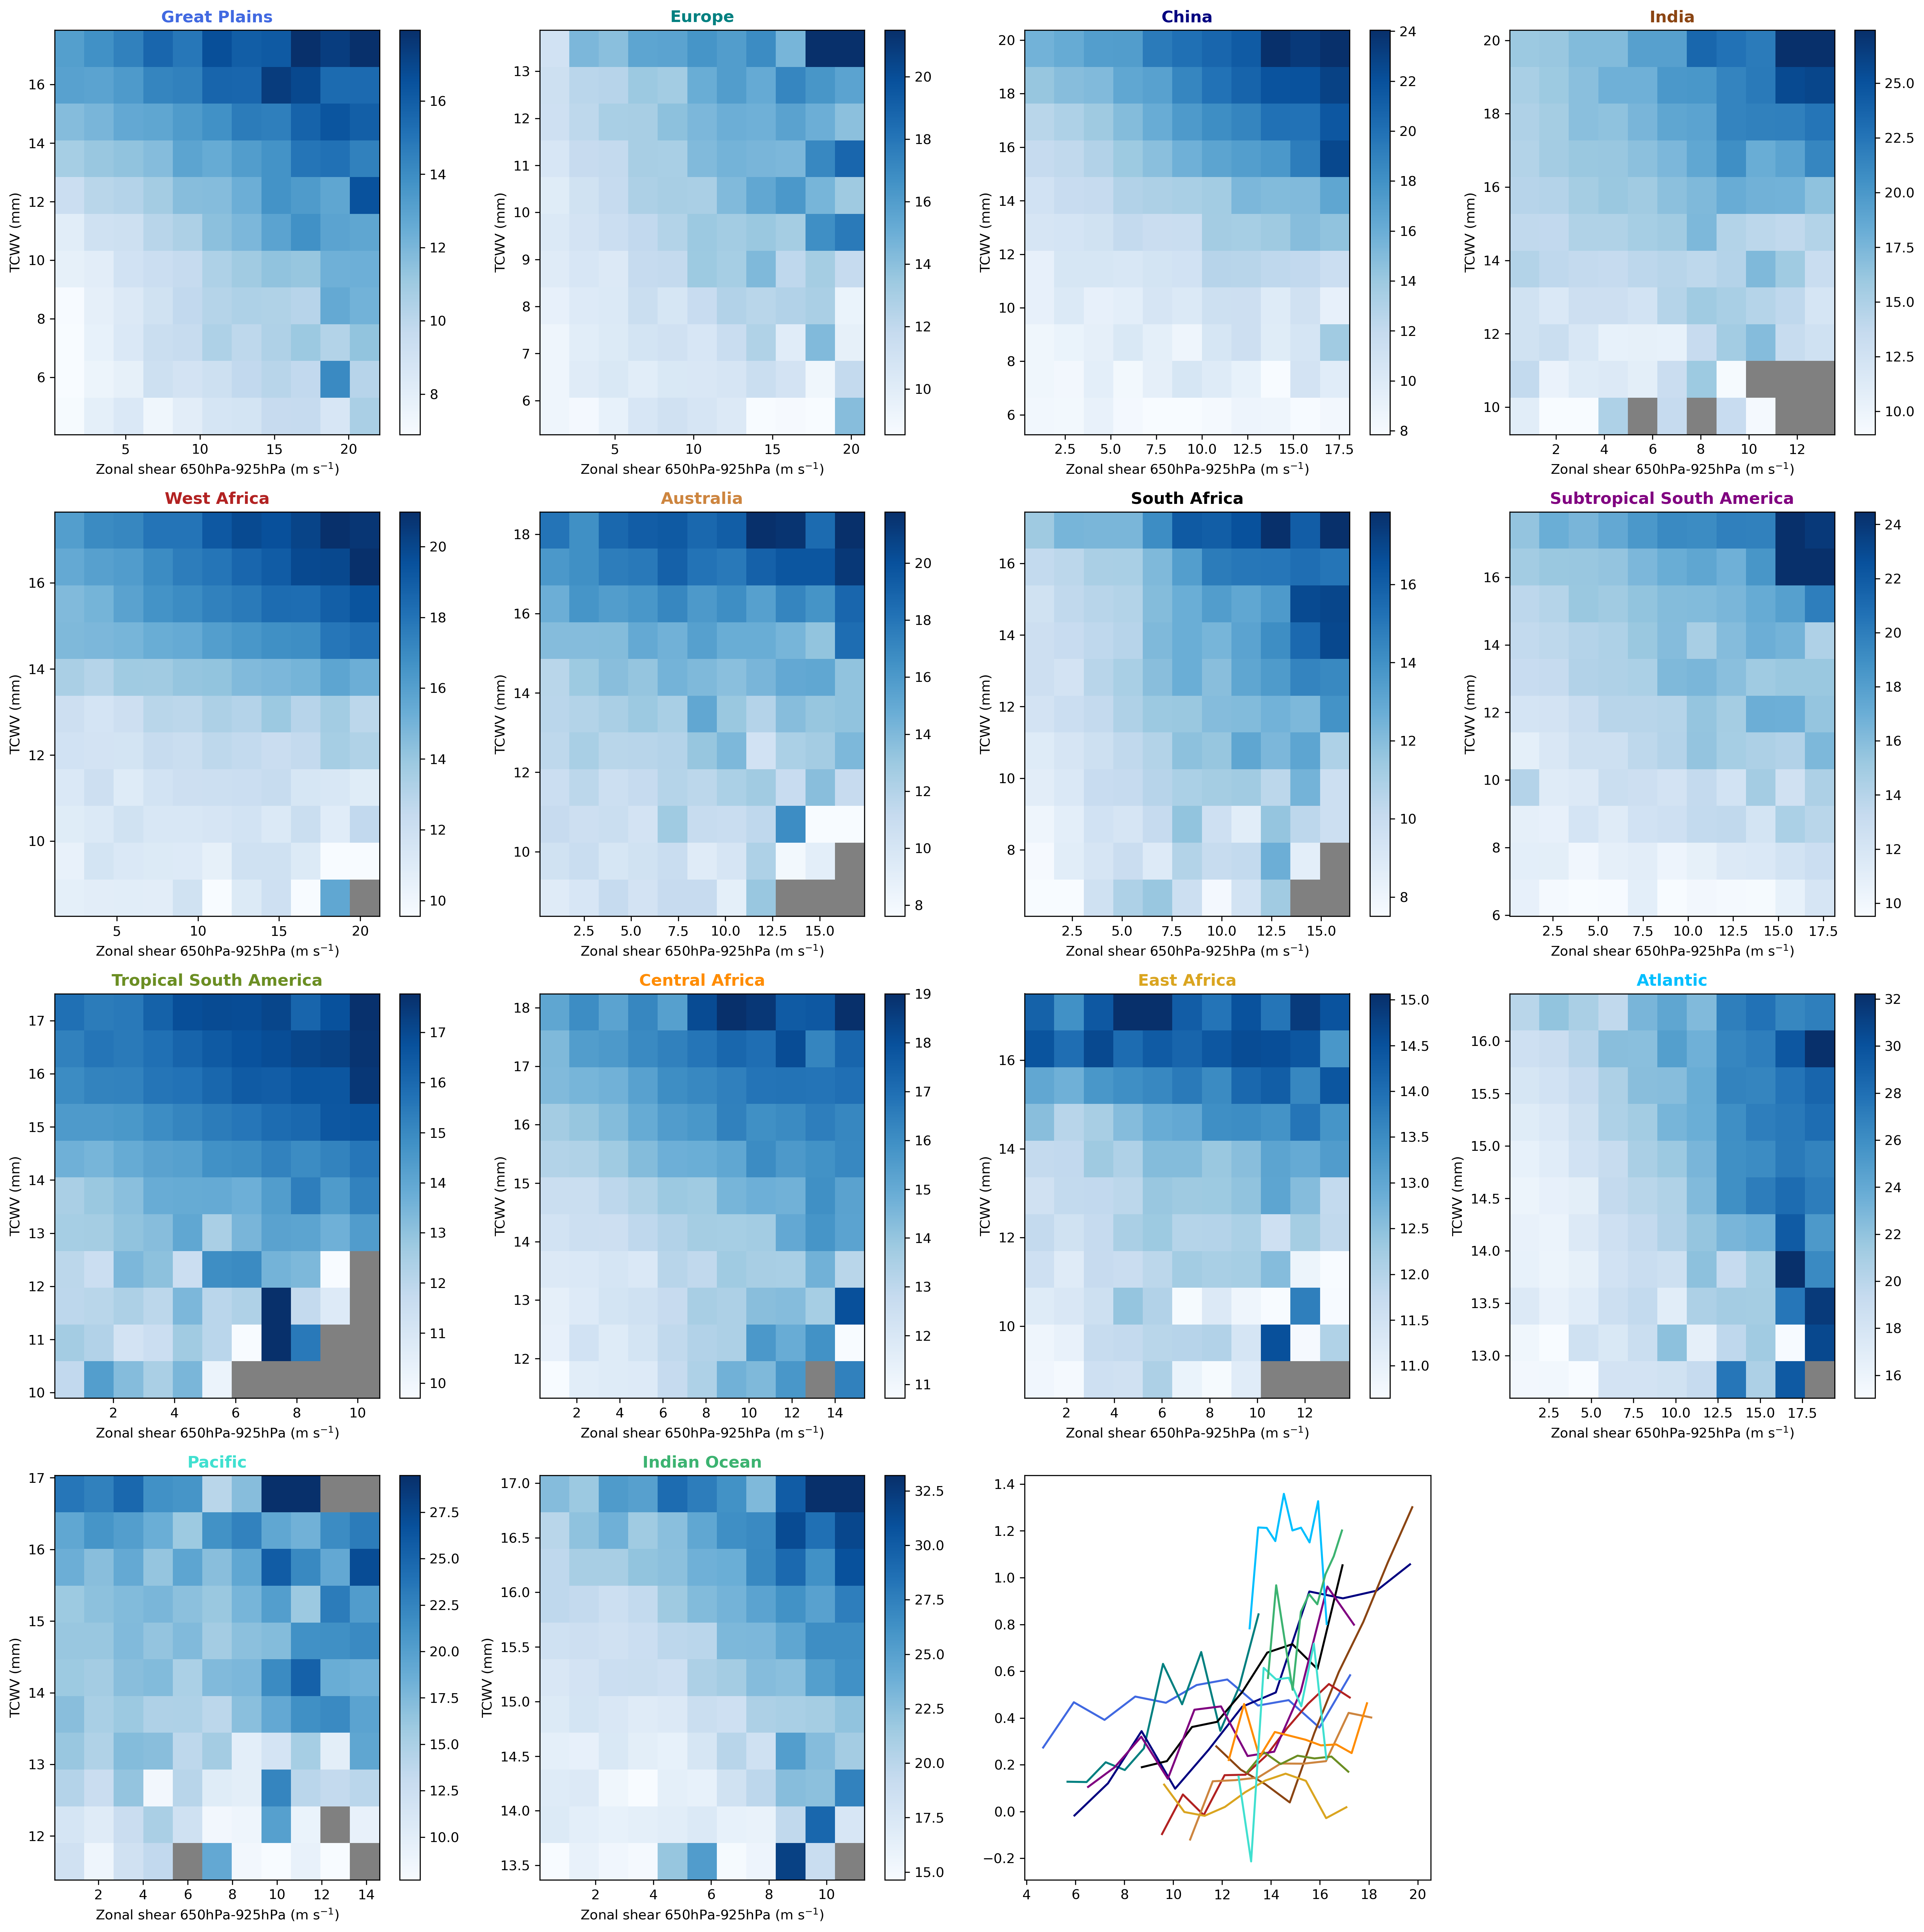

In [29]:
f= plt.figure(figsize=(20,20), dpi=300)
for ids, regs in enumerate(REGIONS.keys()):
    ax = f.add_subplot(4,4,ids+1)
    
    pick = smaller_reg[smaller_reg['region']==regs]
    pick = pick[pick['prcp']>=3]

    factor = REGIONS[regs][-1]
    if factor == -1:
        pick = pick[pick['shear']<=0]
    if factor == 1:
        pick = pick[pick['shear']>=0]
#     tbin = np.linspace(10,20,15)
#     #tbin = np.linspace(10,70,15)
#     sbin = np.linspace(-18,18,15)

    rstyle = style[regs]
    color = rstyle.get("color", None)
    ls = rstyle.get("ls", "-")
    label = rstyle.get("label", regs)

    shear = pick['shear'] * factor

    q = pick['q925']#(pick['q925'] + pick['q850'])/2

    sbin = np.linspace(np.nanpercentile(shear,1), np.nanpercentile(shear,99),12)
    tbin = np.linspace(np.nanpercentile(q,1), np.nanpercentile(q,99),12)
    testbins = [sbin,tbin]
    func1 = lambda y: np.mean(y) #np.percentile(y,95, interpolation='nearest') #np.percentile(y, 95)
    func2 = lambda y: np.sum(np.isfinite(y))
    func3 = lambda y: np.sum(y>1)

    xxu2 = shear.values.astype(np.float64)
    xxtc = q.values
    #xxtc = pick['q925'].values*1000
    xxch = pick['prcp'].values
    
   # ipdb.set_trace()
    
    ret = binned_statistic_2d(xxu2, xxtc, xxch, statistic=func1, bins=testbins)
    count = binned_statistic_2d(xxu2, xxtc, xxch, statistic=func2, bins=testbins)
    # thresh = binned_statistic_2d(xxu2, xxtc, xxch, statistic=func3, bins=testbins)

    dd=ret.statistic.T
    valid = count.statistic.T
    dd[valid<5] = np.nan

    mp = plt.pcolormesh(testbins[0], testbins[1], dd, cmap='Blues', vmin=np.nanpercentile(dd,1), vmax=np.nanpercentile(dd,99)) #vmax=p2-1, vmin=0.5  ##p2-1
 
    plt.colorbar(mp)
    ax.set_title(label, color=color, fontweight="bold")
    
    ax.set_ylabel('TCWV (mm)')
    ax.set_xlabel(r'Zonal shear 650hPa-925hPa (m s$^{-1}$)')
    
    ax.set_facecolor('grey')

    if ids == 0:
        ax1 = f.add_subplot(4,4,ids+15)

    x = np.arange(dd.shape[1])   # [0,1,2,3,4,5]

    slopes = np.full(dd.shape[0], np.nan)
    pvals  = np.full(dd.shape[0], np.nan)

    for j in range(dd.shape[0]):
        y = dd[j, :]
        res = linregress(x, y)
        slopes[j] = res.slope
        pvals[j] = res.pvalue

    print("slopes:", slopes)
    print("pvals:", pvals)

    ax1.plot(testbins[1][0:-1]+(testbins[1][1::]-testbins[1][0:-1])/2, slopes, color=color)
plt.tight_layout()
print()
f.savefig(paths.shear_figs + '/2d_hist_precip_q925.png')

slopes: [-404.68018412   12.41552416 1465.79475989 1016.78886502 1592.61671635
 1412.33795066 1625.60001265 3236.93375496 3290.15795069 2816.724403
 2087.8850462 ]
pvals: [3.15292724e-02 9.74621660e-01 1.61572733e-04 1.30666043e-02
 2.07837113e-05 5.29245622e-05 5.53063156e-06 1.81481427e-06
 2.00659801e-06 3.78561798e-07 1.72118798e-02]
slopes: [          nan 1068.45254836  257.46887032  740.10687075  422.36483658
  487.12501204  756.52830724  401.74959862  386.11678495  -16.69894049
  -33.40515926]
pvals: [           nan 9.28964621e-03 1.68966914e-02 5.28136026e-05
 3.97379879e-03 2.16889310e-05 1.81853907e-05 3.48390133e-02
 4.54608774e-04 9.57462790e-01 9.38811048e-01]
slopes: [ 175.27747065  726.00470537 1068.06935136  480.1218714   210.17429108
  149.9917855   688.19959473  199.09700161  235.9695139    29.12257433
 -969.20025356]
pvals: [0.62901329 0.00664234 0.00568391 0.01229628 0.32515795 0.49175123
 0.00306811 0.24928277 0.36420603 0.92575759 0.05721768]
slopes: [          na

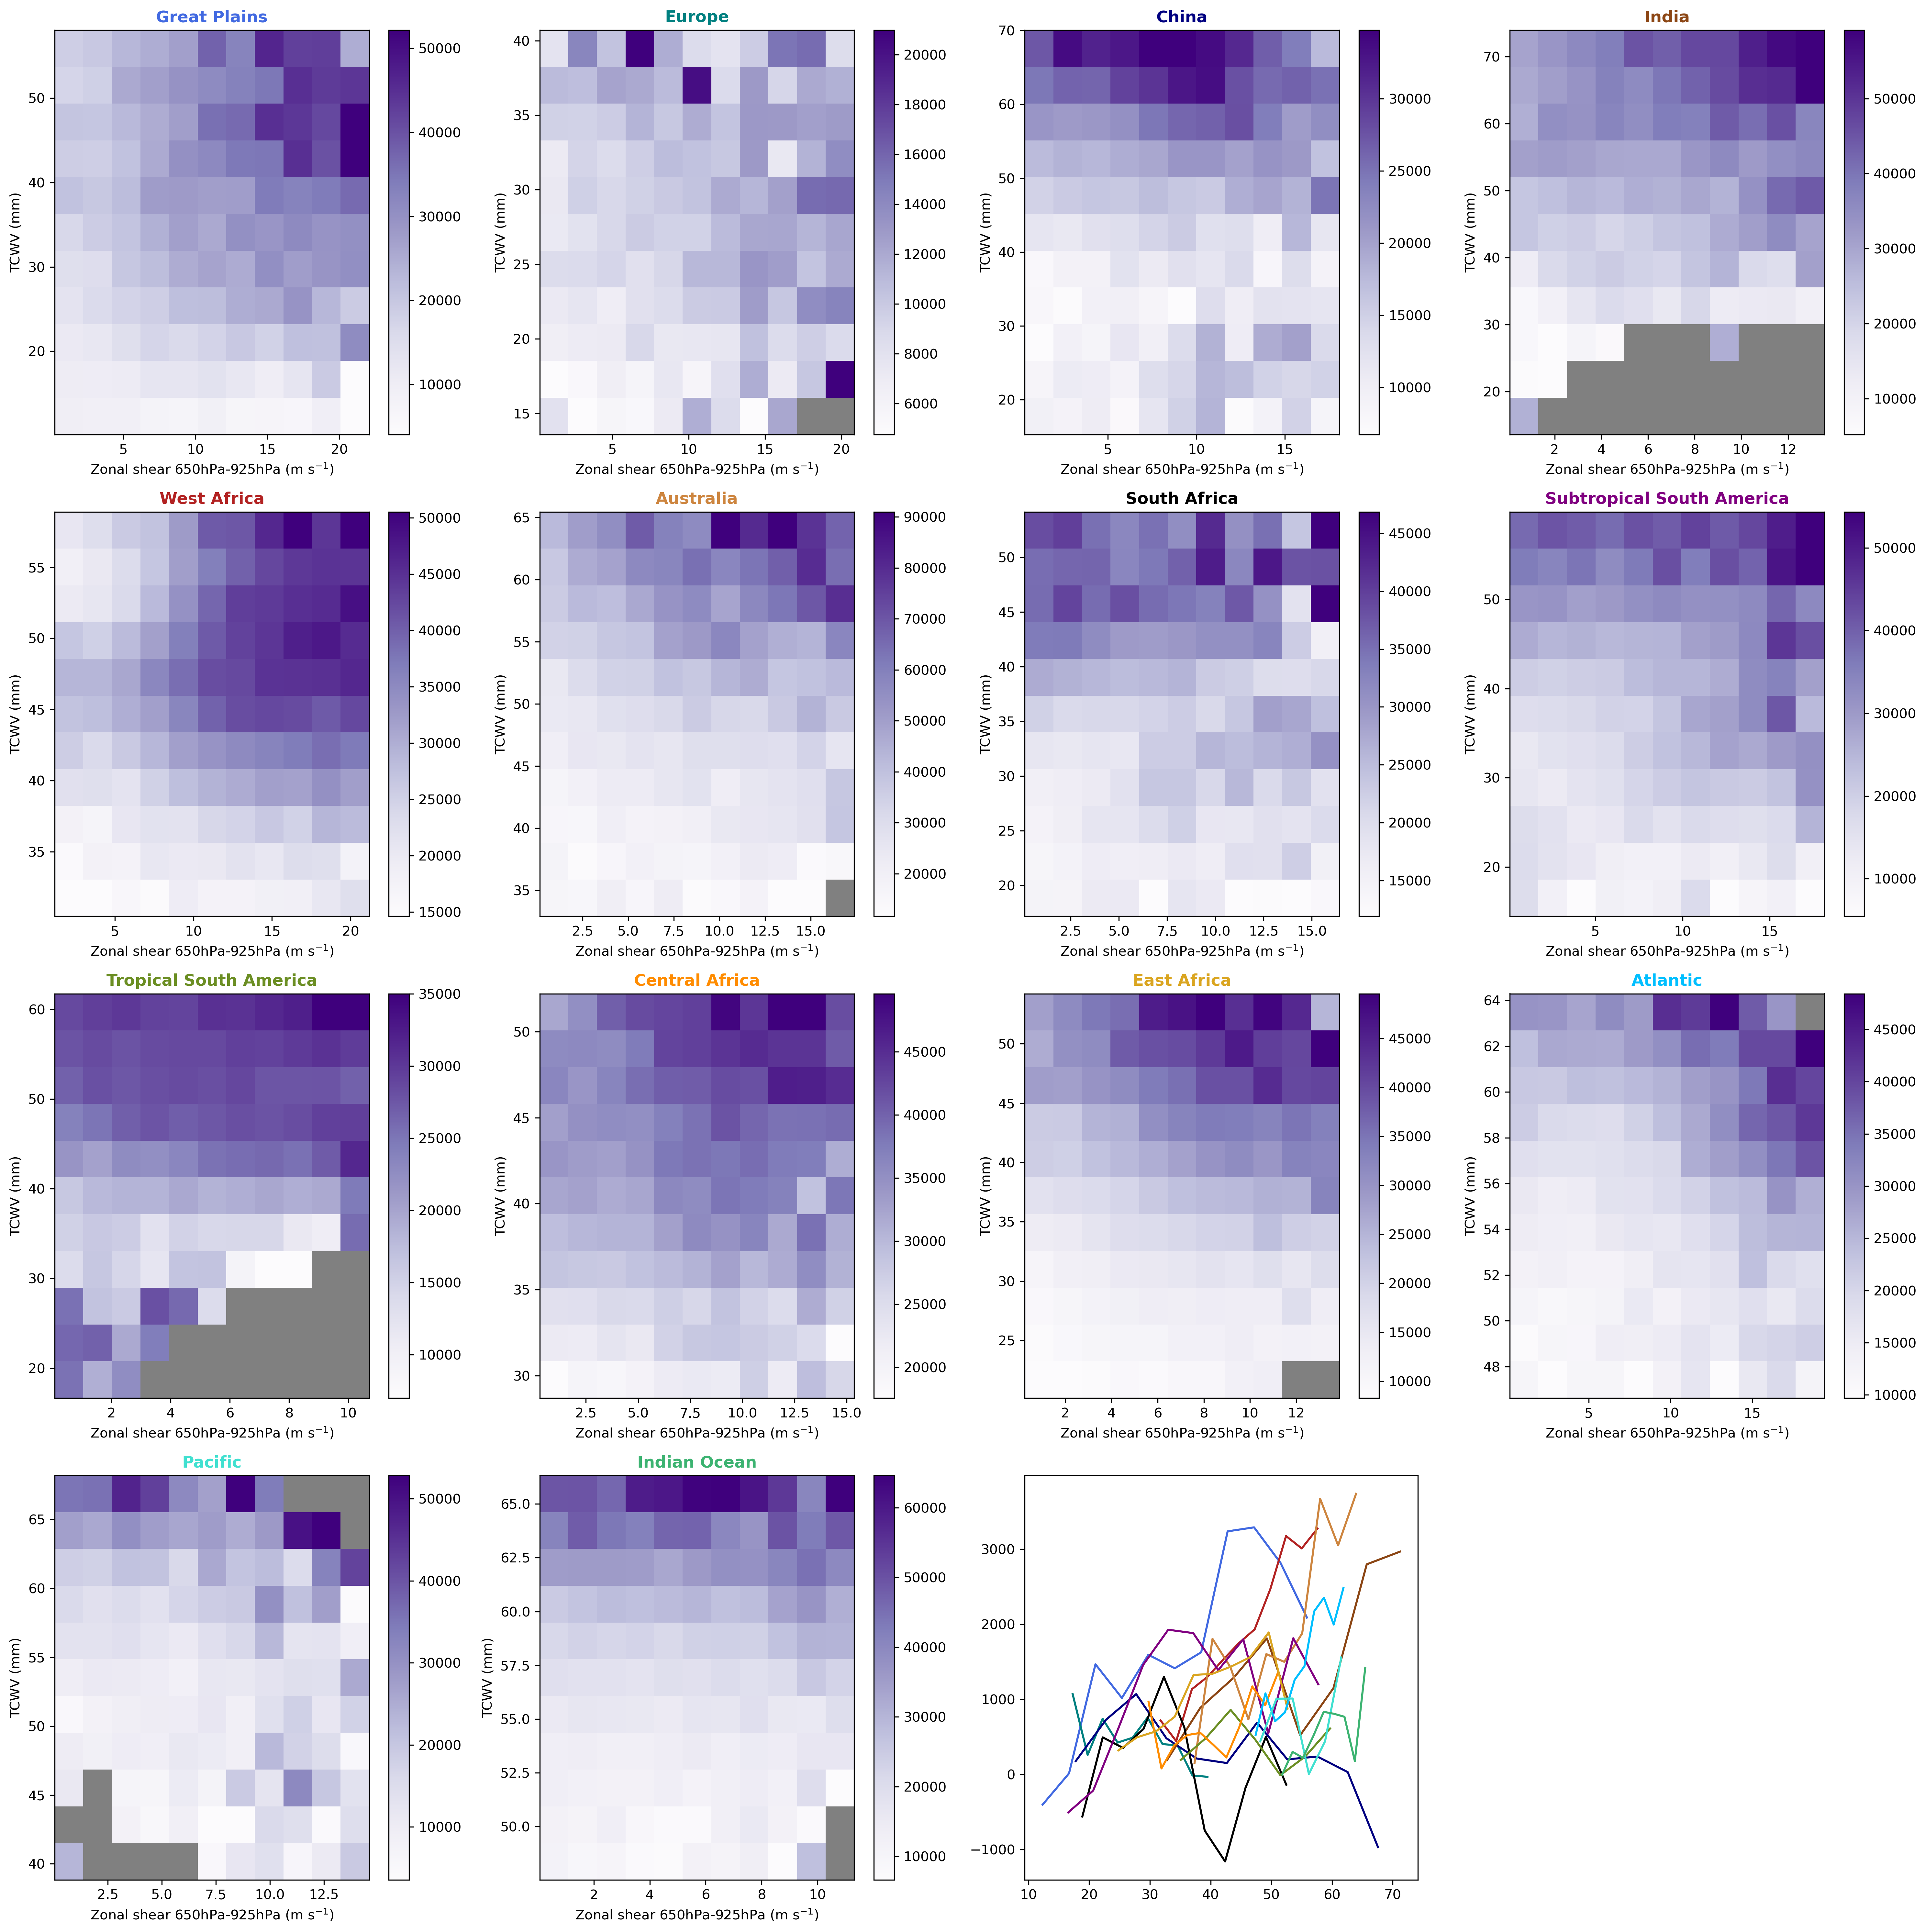

In [35]:
f= plt.figure(figsize=(20,20), dpi=300)
for ids, regs in enumerate(REGIONS.keys()):
    ax = f.add_subplot(4,4,ids+1)
    
    pick = smaller_reg[smaller_reg['region']==regs]
    pick = pick[pick['prcp']>=3]

    factor = REGIONS[regs][-1]
    if factor == -1:
        pick = pick[pick['shear']<=0]
    if factor == 1:
        pick = pick[pick['shear']>=0]
#     tbin = np.linspace(10,20,15)
#     #tbin = np.linspace(10,70,15)
#     sbin = np.linspace(-18,18,15)

    rstyle = style[regs]
    color = rstyle.get("color", None)
    ls = rstyle.get("ls", "-")
    label = rstyle.get("label", regs)

    shear = pick['shear'] * factor

    q = pick['tcwv']#(pick['q925'] + pick['q850'])/2

    sbin = np.linspace(np.nanpercentile(shear,1), np.nanpercentile(shear,99),12)
    tbin = np.linspace(np.nanpercentile(q,1), np.nanpercentile(q,99),12)
    testbins = [sbin,tbin]
    func1 = lambda y: np.mean(y) #np.percentile(y,95, interpolation='nearest') #np.percentile(y, 95)
    func2 = lambda y: np.sum(np.isfinite(y))
    func3 = lambda y: np.sum(y>1)

    xxu2 = shear.values.astype(np.float64)
    xxtc = q.values
    #xxtc = pick['q925'].values*1000
    xxch = pick['area'].values
    
   # ipdb.set_trace()
    
    ret = binned_statistic_2d(xxu2, xxtc, xxch, statistic=func1, bins=testbins)
    count = binned_statistic_2d(xxu2, xxtc, xxch, statistic=func2, bins=testbins)
    # thresh = binned_statistic_2d(xxu2, xxtc, xxch, statistic=func3, bins=testbins)

    dd=ret.statistic.T
    valid = count.statistic.T
    dd[valid<5] = np.nan

    mp = plt.pcolormesh(testbins[0], testbins[1], dd, cmap='Purples', vmin=np.nanpercentile(dd,1), vmax=np.nanpercentile(dd,99)) #vmax=p2-1, vmin=0.5  ##p2-1
 
    plt.colorbar(mp)
    ax.set_title(label, color=color, fontweight="bold")
    
    ax.set_ylabel('TCWV (mm)')
    ax.set_xlabel(r'Zonal shear 650hPa-925hPa (m s$^{-1}$)')
    
    ax.set_facecolor('grey')

    if ids == 0:
        ax1 = f.add_subplot(4,4,ids+15)

    x = np.arange(dd.shape[1])   # [0,1,2,3,4,5]

    slopes = np.full(dd.shape[0], np.nan)
    pvals  = np.full(dd.shape[0], np.nan)

    for j in range(dd.shape[0]):
        y = dd[j, :]
        res = linregress(x, y)
        slopes[j] = res.slope
        pvals[j] = res.pvalue

    print("slopes:", slopes)
    print("pvals:", pvals)

    ax1.plot(testbins[1][0:-1]+(testbins[1][1::]-testbins[1][0:-1])/2, slopes, color=color)
plt.tight_layout()
print()
f.savefig(paths.shear_figs + '/2d_hist_area50_tcwv.png')

In [33]:
smaller_reg[smaller_reg['region']==regs]['area']

,area,area
18300788,27220.755859,9128.765625
18300799,29883.984375,5432.872559
18300803,187984.140625,89778.695312
18300817,167173.218750,74244.218750
18300830,6866.885742,3678.232910
...,...,...
19425046,11792.294922,8422.843750
19425050,33123.636719,18043.748047
19425057,9643.781250,4451.069824
19425067,19506.273438,14691.904297


slopes: [-0.27997546 -0.11051887 -0.18081718 -0.29822916 -0.13502911  0.12753756
  0.13306499]
pvals: [0.01191127 0.45434471 0.21298852 0.04516283 0.21795832 0.03646161
 0.57333753]
slopes: [-0.7314525  -0.05427079 -0.01678006  0.41793758  0.70491076  1.03790891
  1.40899283]
pvals: [3.25824301e-02 6.92376710e-01 8.67625452e-01 1.71759028e-03
 2.30698129e-04 1.54796715e-03 3.20020120e-02]
slopes: [1.4844754  1.66260436 1.81316401 1.88393381 1.83543934 1.86137973
 2.19732702]
pvals: [3.07964736e-04 9.20735168e-06 3.30713135e-05 2.41350816e-05
 4.25872938e-05 7.90007440e-07 2.19992857e-04]
slopes: [0.65797877 0.73029347 0.80827701 0.98181674 1.14297353 1.43036485
 1.65826964]
pvals: [2.42288952e-03 5.46304111e-04 1.05354538e-04 1.17816574e-04
 2.30763881e-06 1.11119478e-05 8.08847994e-07]


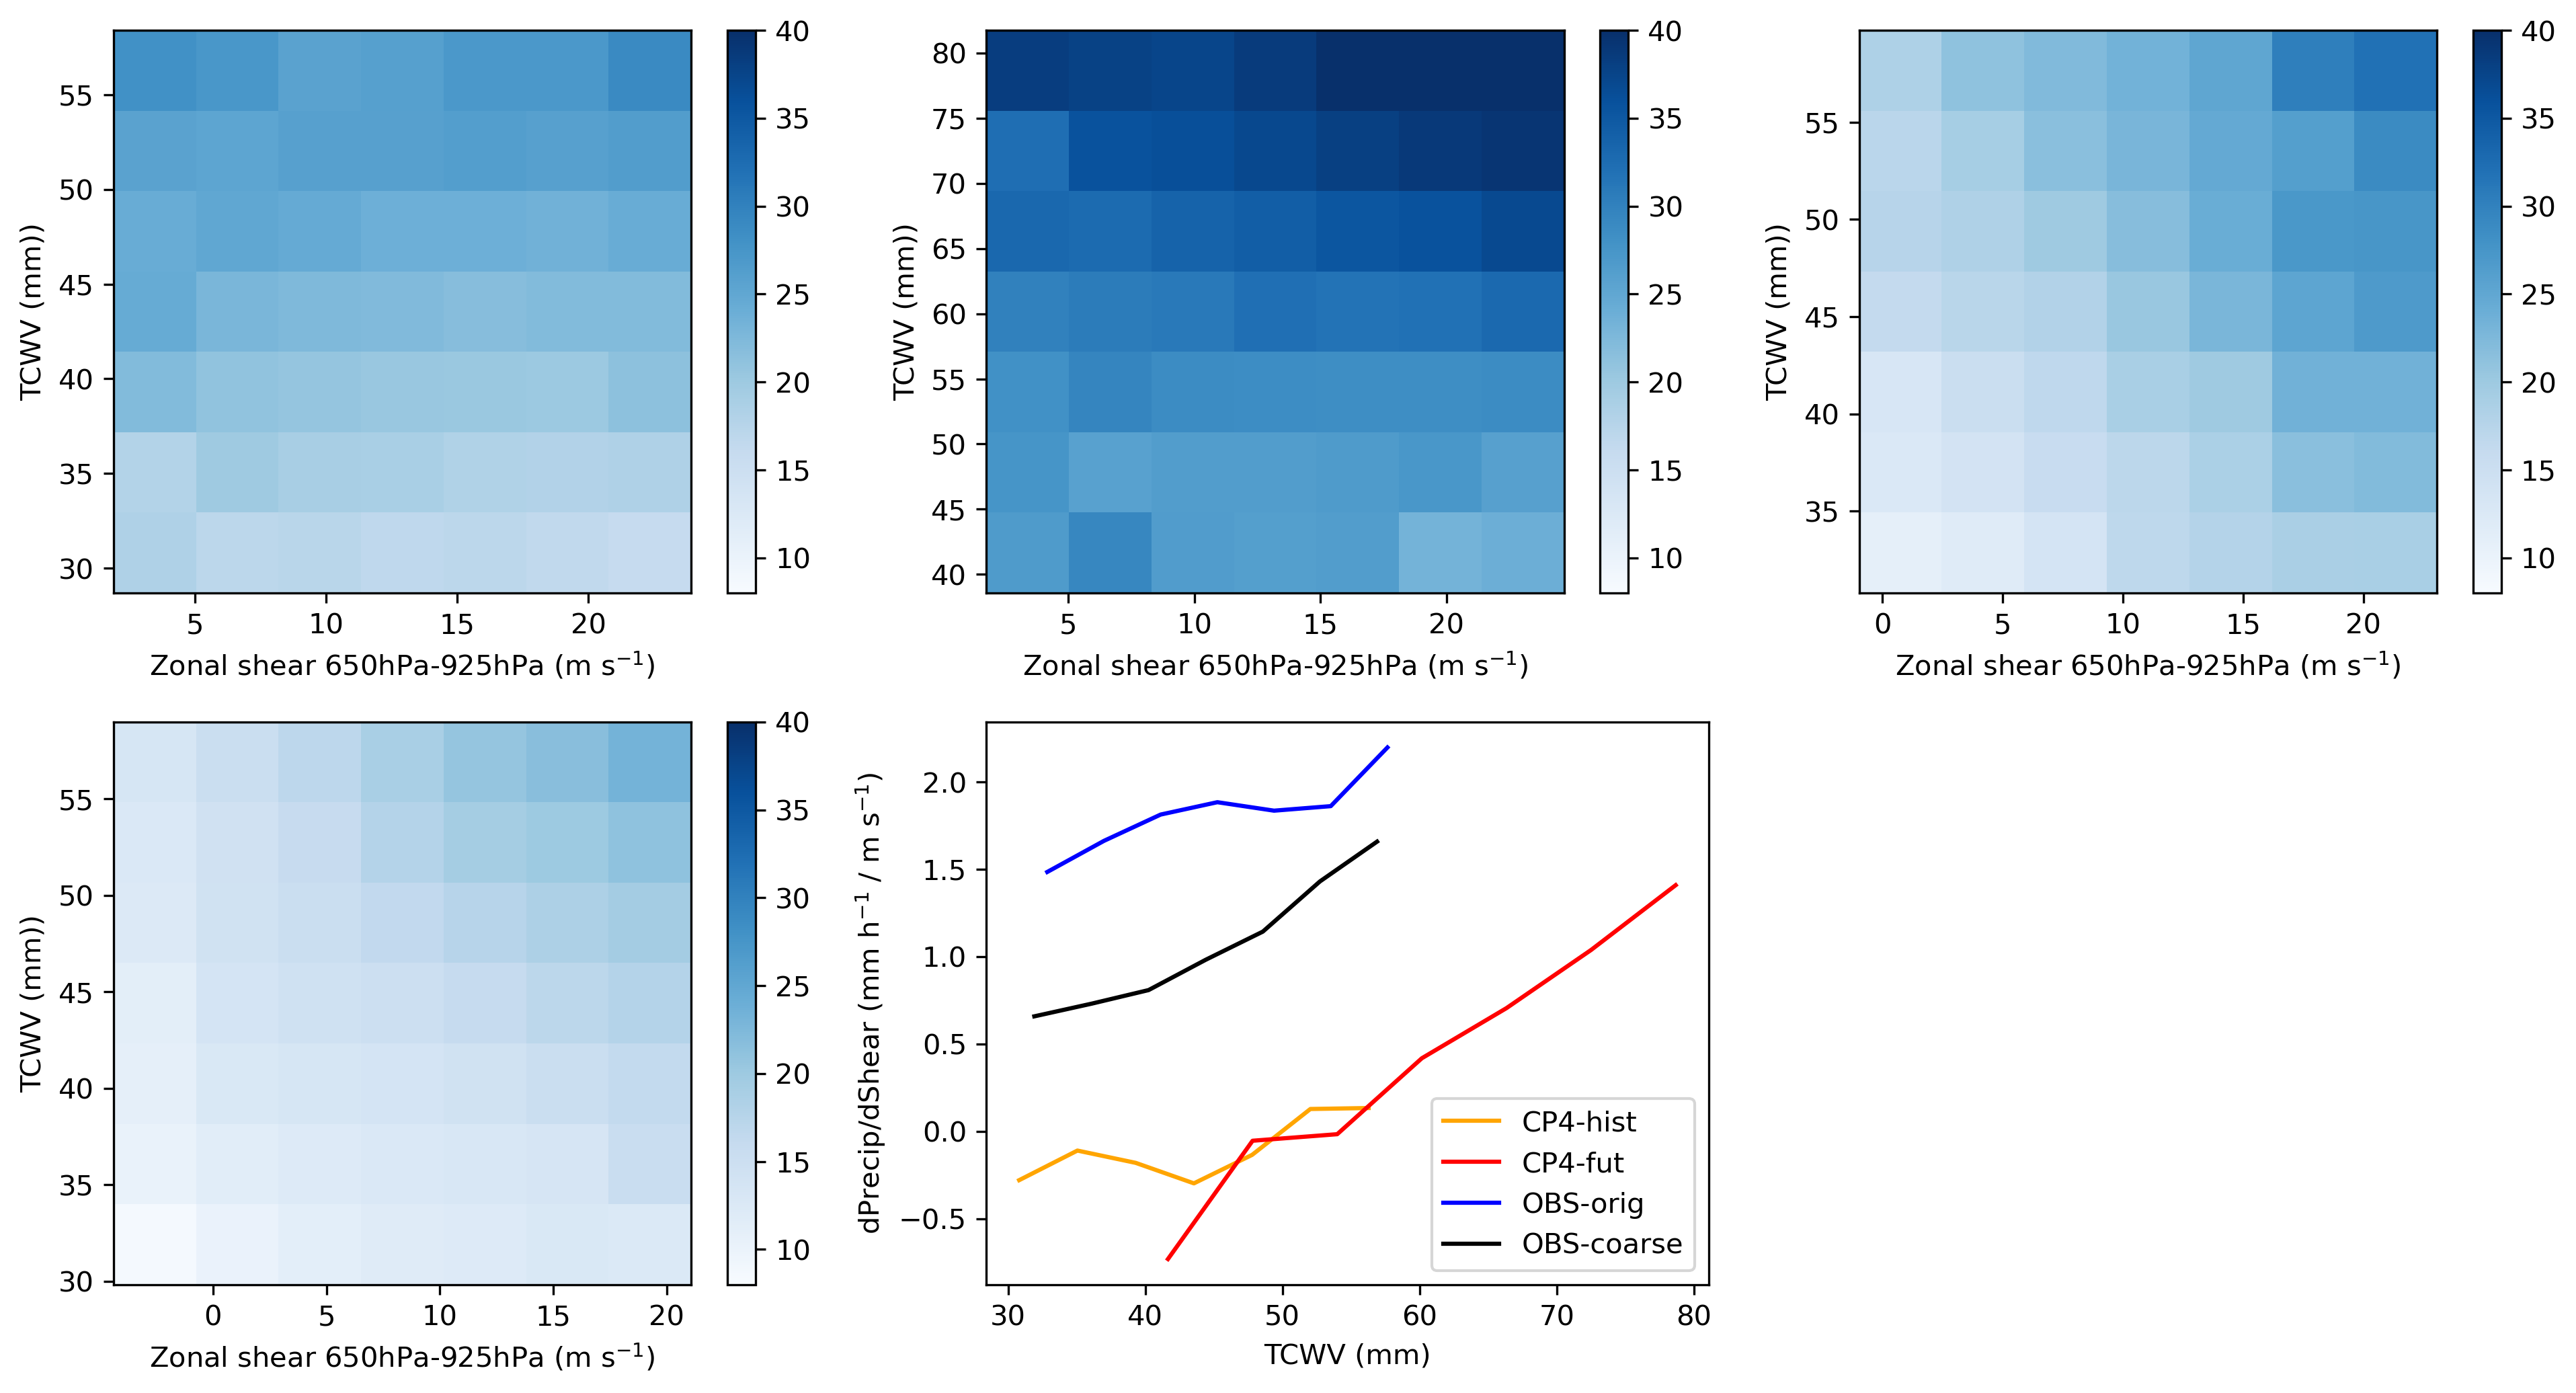

In [44]:
cs = ['orange', 'red', 'blue', 'black']
labs = ['CP4-hist' , 'CP4-fut', 'OBS-orig', 'OBS-coarse']

f= plt.figure(figsize=(13,10), dpi=300)

for ids, regs in enumerate([cp4h, cp4f, obs, smaller_reg[smaller_reg['region']=='WAf']]):
    ax = f.add_subplot(3,3,ids+1)
    
    pick = regs
    pick = pick[pick['prcp']>=2]

    factor = 1
    if ids == 3:
        factor = -1
#     tbin = np.linspace(10,20,15)
#     #tbin = np.linspace(10,70,15)
#     sbin = np.linspace(-18,18,15)

    sbin = np.linspace(np.nanpercentile(pick['shear']*factor,1), np.nanpercentile(pick['shear']*factor,99),8)
    tbin = np.linspace(np.nanpercentile(pick['tcwv'],1), np.nanpercentile(pick['tcwv'],99),8)
    #tbin = np.linspace(np.nanpercentile(pick['tcwv'],1), np.nanpercentile(pick['tcwv'],99),12)
    testbins = [sbin,tbin]
    func1 = lambda y: np.mean(y) #np.percentile(y,95, interpolation='nearest') #np.percentile(y, 95)
    func2 = lambda y: np.sum(np.isfinite(y))
    func3 = lambda y: np.sum(y>1)

    xxu2 = pick['shear'].values*factor

    #xxtc = pick['tcwv'].values
    xxtc = pick['tcwv'].values
    xxch = pick['prcp'].values
    
   # ipdb.set_trace()
    
    ret = binned_statistic_2d(xxu2, xxtc, xxch, statistic=func1, bins=testbins)
    count = binned_statistic_2d(xxu2, xxtc, xxch, statistic=func2, bins=testbins)
    # thresh = binned_statistic_2d(xxu2, xxtc, xxch, statistic=func3, bins=testbins)

    dd=ret.statistic.T
    valid = count.statistic.T
    dd[valid<15] = np.nan

    mp = plt.pcolormesh(testbins[0], testbins[1], dd, cmap='Blues', vmin=8, vmax=40) #vmax=p2-1, vmin=0.5  ##p2-1
    #plt.title(regs+' IQR ='+str(np.round(np.nanpercentile(xxch,75)-np.nanpercentile(xxch,25),2))+'K')
    plt.colorbar(mp)
    #plt.title(regs+' Pmax stddev: '+str(np.round(np.std(xxch),2)))
    
    ax.set_ylabel('TCWV (mm))')
    ax.set_xlabel(r'Zonal shear 650hPa-925hPa (m s$^{-1}$)')
    
    ax.set_facecolor('grey')
    #ipdb.set_trace()
    
    if ids == 0:
        ax1 = f.add_subplot(3,3,ids+5)

    x = np.arange(dd.shape[1])   # [0,1,2,3,4,5]

    slopes = np.full(dd.shape[0], np.nan)
    pvals  = np.full(dd.shape[0], np.nan)

    for j in range(dd.shape[0]):
        y = dd[j, :]
        res = linregress(x, y)
        slopes[j] = res.slope
        pvals[j] = res.pvalue

    print("slopes:", slopes)
    print("pvals:", pvals)

    mp = ax1.plot(testbins[1][0:-1]+(testbins[1][1::]-testbins[1][0:-1])/2, slopes, color=cs[ids], label=labs[ids])
    ax1.set_ylabel(r'dPrecip/dShear (mm h$^{-1}$ / m s$^{-1}$)')
    ax1.set_xlabel('TCWV (mm)')
ax1.legend()
plt.tight_layout()

f.savefig(paths.shear_figs + '/2d_hist_prcp_tcwv_cp4.png')

slopes: [1016.35501943 1116.27967778 1603.32134023 1325.43134168 1034.18158631
  773.4885927   139.06169368]
pvals: [3.24392871e-04 1.23907419e-04 9.15091681e-05 6.84185746e-04
 1.44088696e-05 1.59409769e-03 2.91239512e-01]
slopes: [ 684.90239099  687.11284051 1131.89142382 1980.91463386 2322.42380869
 2204.83104096 2344.79832957]
pvals: [2.44859085e-01 8.66666053e-02 1.28191797e-03 4.32440817e-05
 1.10502471e-04 1.55359894e-05 2.29512441e-03]
slopes: [3220.39227919 5069.77748997 6535.58025833 7852.02990795 8445.32209326
 6090.09175675 6000.69399985]
pvals: [4.66407590e-03 7.76475867e-04 1.15332646e-04 2.73083635e-05
 4.44491361e-04 9.52319853e-06 6.40436577e-05]
slopes: [1673.46794555 2110.32157086 3015.44765429 3432.9323896  4203.59496064
 5776.20836697 5824.71534702]
pvals: [3.85070246e-04 1.19693790e-05 4.38772877e-06 1.90271075e-04
 1.18378683e-04 5.85348509e-05 3.32170545e-05]


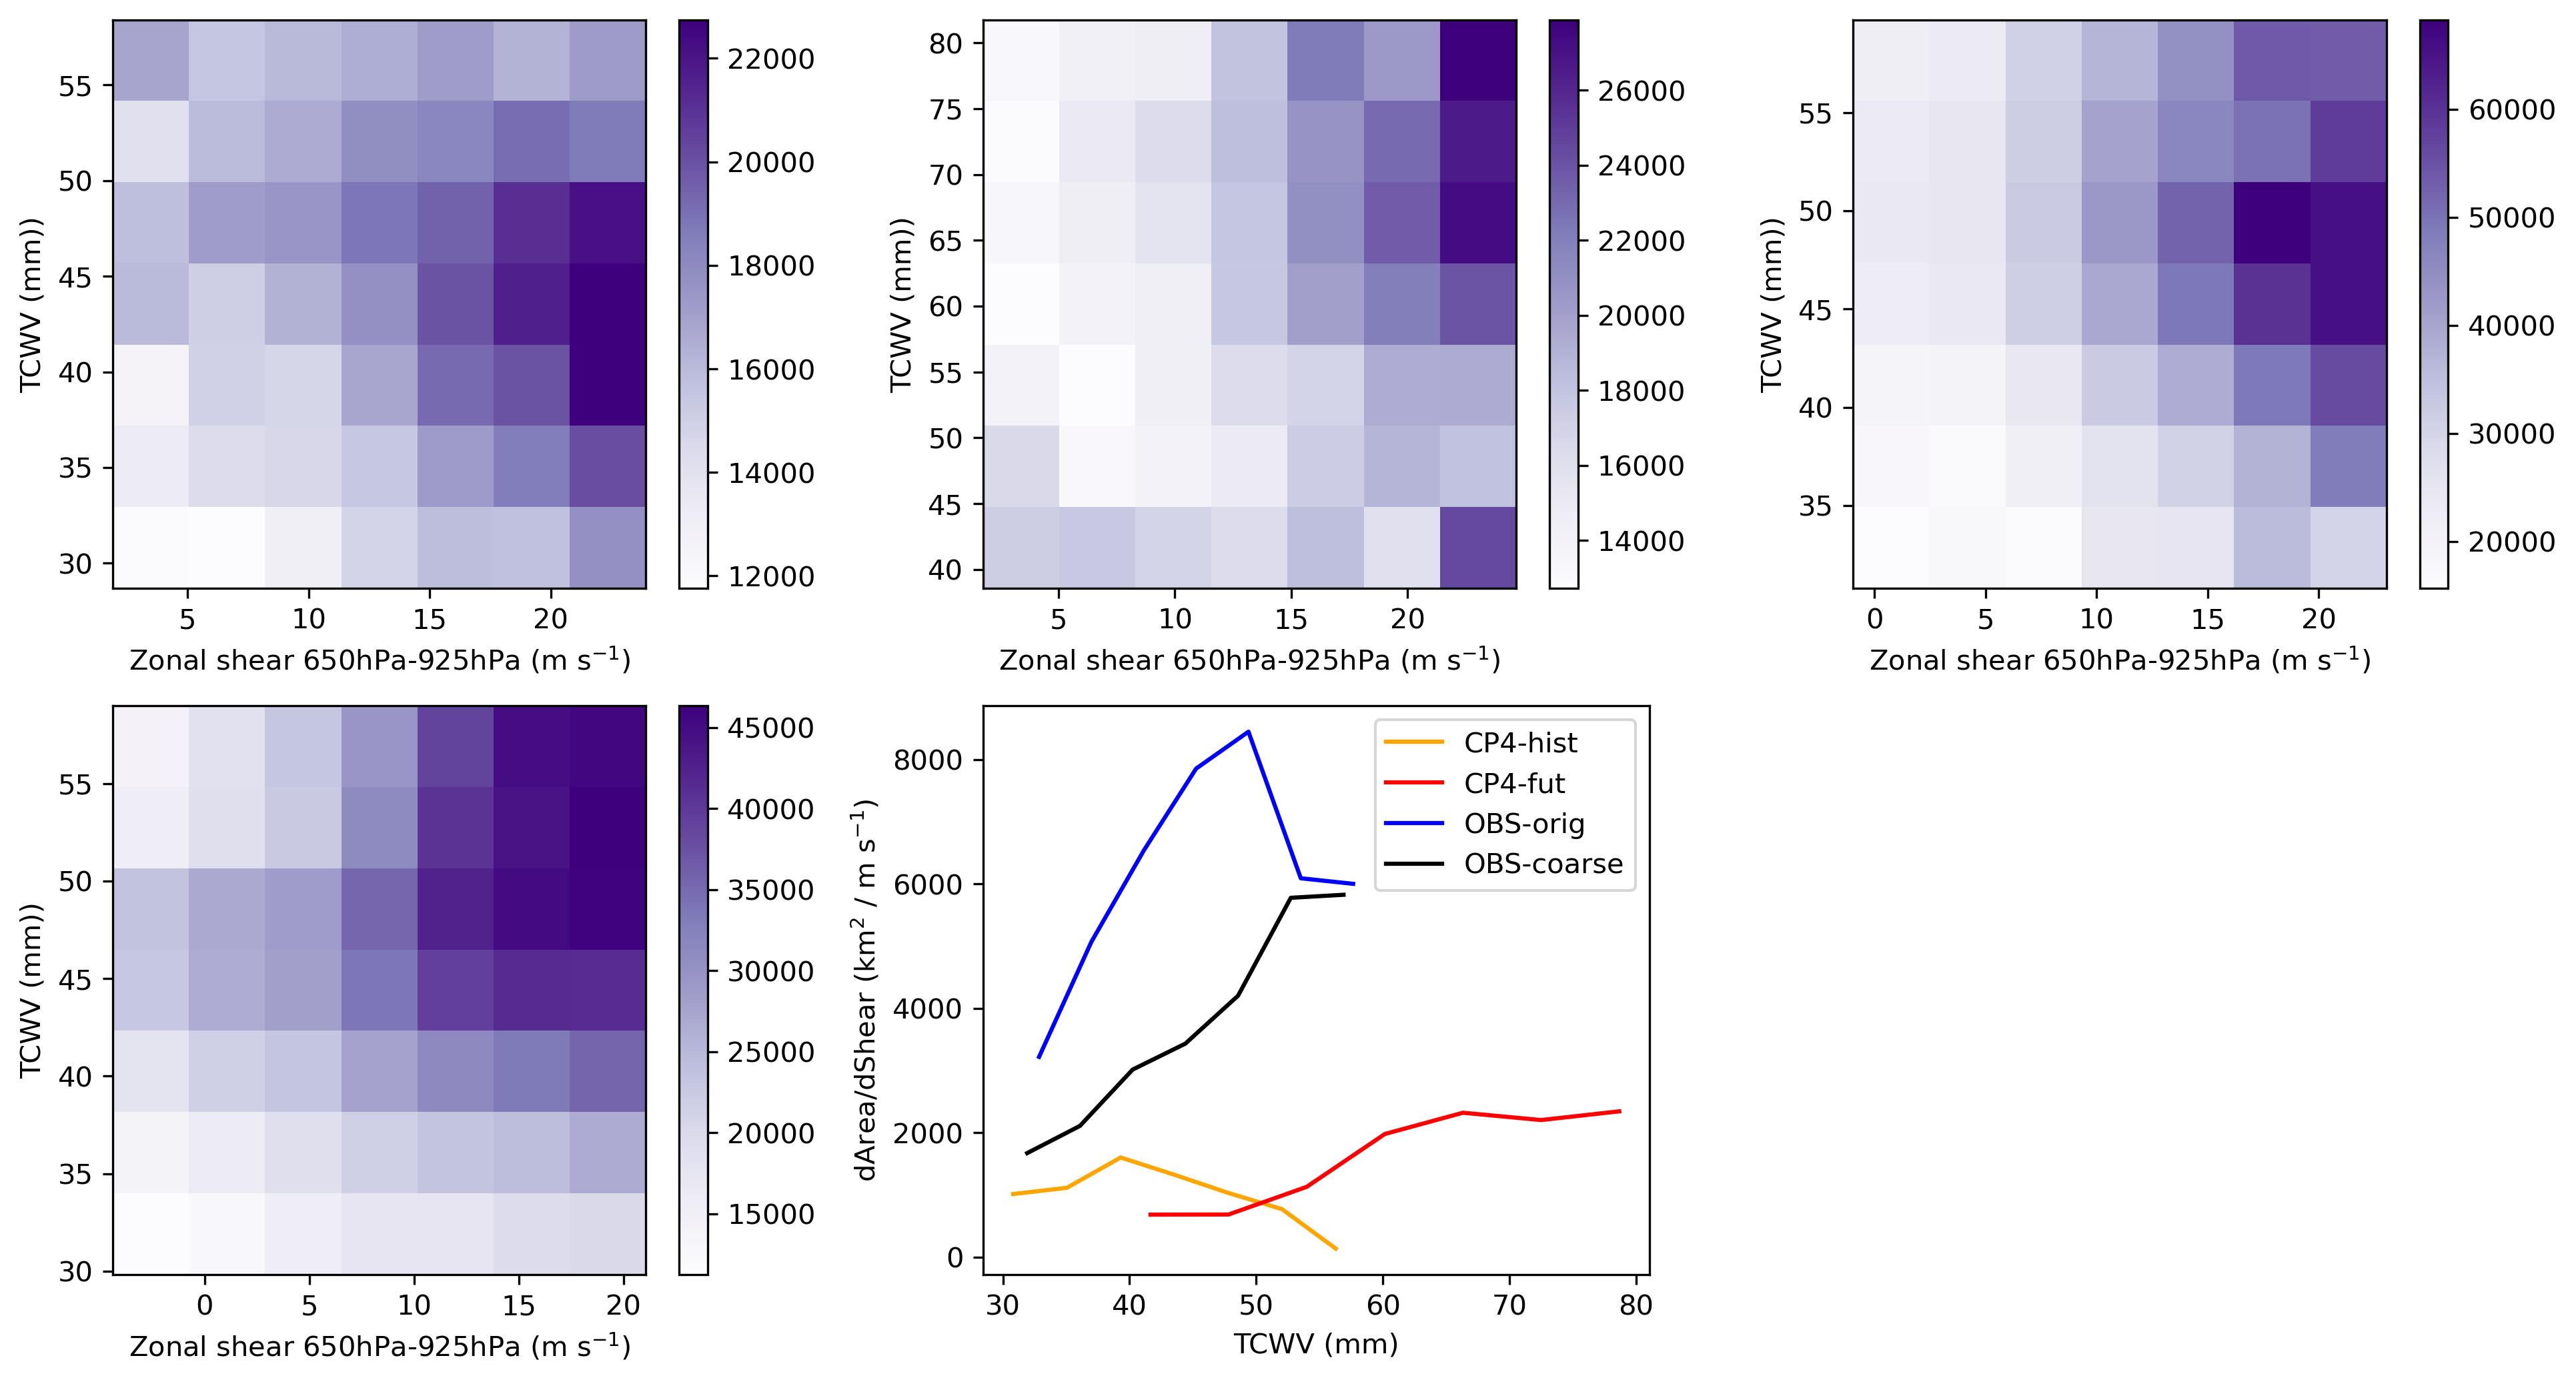

In [47]:
cs = ['orange', 'red', 'blue', 'black']
labs = ['CP4-hist' , 'CP4-fut', 'OBS-orig', 'OBS-coarse']

f= plt.figure(figsize=(13,10), dpi=300)

for ids, regs in enumerate([cp4h, cp4f, obs, smaller_reg[smaller_reg['region']=='WAf']]):
    ax = f.add_subplot(3,3,ids+1)
    
    pick = regs
    pick = pick[pick['prcp']>=2]

    factor = 1
    if ids == 3:
        factor = -1
#     tbin = np.linspace(10,20,15)
#     #tbin = np.linspace(10,70,15)
#     sbin = np.linspace(-18,18,15)

    sbin = np.linspace(np.nanpercentile(pick['shear']*factor,1), np.nanpercentile(pick['shear']*factor,99),8)
    tbin = np.linspace(np.nanpercentile(pick['tcwv'],1), np.nanpercentile(pick['tcwv'],99),8)
    #tbin = np.linspace(np.nanpercentile(pick['tcwv'],1), np.nanpercentile(pick['tcwv'],99),12)
    testbins = [sbin,tbin]
    func1 = lambda y: np.mean(y) #np.percentile(y,95, interpolation='nearest') #np.percentile(y, 95)
    func2 = lambda y: np.sum(np.isfinite(y))
    func3 = lambda y: np.sum(y>1)

    xxu2 = pick['shear'].values*factor

    #xxtc = pick['tcwv'].values
    xxtc = pick['tcwv'].values
    xxch = pick['area'].values
    
   # ipdb.set_trace()
    
    ret = binned_statistic_2d(xxu2, xxtc, xxch, statistic=func1, bins=testbins)
    count = binned_statistic_2d(xxu2, xxtc, xxch, statistic=func2, bins=testbins)
    # thresh = binned_statistic_2d(xxu2, xxtc, xxch, statistic=func3, bins=testbins)

    dd=ret.statistic.T
    valid = count.statistic.T
    dd[valid<15] = np.nan

    mp = plt.pcolormesh(testbins[0], testbins[1], dd, cmap='Purples', vmin=np.nanpercentile(dd,1), vmax=np.nanpercentile(dd,99)) #vmax=p2-1, vmin=0.5  ##p2-1
    #plt.title(regs+' IQR ='+str(np.round(np.nanpercentile(xxch,75)-np.nanpercentile(xxch,25),2))+'K')
    plt.colorbar(mp)
    #plt.title(regs+' Pmax stddev: '+str(np.round(np.std(xxch),2)))
    
    ax.set_ylabel('TCWV (mm))')
    ax.set_xlabel(r'Zonal shear 650hPa-925hPa (m s$^{-1}$)')
    
    ax.set_facecolor('grey')
    #ipdb.set_trace()
    
    if ids == 0:
        ax1 = f.add_subplot(3,3,ids+5)

    x = np.arange(dd.shape[1])   # [0,1,2,3,4,5]

    slopes = np.full(dd.shape[0], np.nan)
    pvals  = np.full(dd.shape[0], np.nan)

    for j in range(dd.shape[0]):
        y = dd[j, :]
        res = linregress(x, y)
        slopes[j] = res.slope
        pvals[j] = res.pvalue

    print("slopes:", slopes)
    print("pvals:", pvals)

    mp = ax1.plot(testbins[1][0:-1]+(testbins[1][1::]-testbins[1][0:-1])/2, slopes, color=cs[ids], label=labs[ids])
    ax1.set_ylabel(r'dArea/dShear (km$^{2}$ / m s$^{-1}$)')
    ax1.set_xlabel('TCWV (mm)')
ax1.legend()
plt.tight_layout()

f.savefig(paths.shear_figs + '/2d_hist_area_tcwv_cp4.png')

In [148]:
plot_regs = {}

for ids, regs in enumerate(MREGIONS.keys()):
    
    pick = smaller_reg[regs]
    pick = pick[pick['prcp']>=1]

    factor = MREGIONS[regs][-1]
    if factor == -1:
        pick = pick[(pick['u650']<=0) & (pick['shear']<=0)]
    if factor == 1:
        pick = pick[(pick['u650']>=0) & (pick['shear']>=0)]

    pick['shear'] = pick['shear'] * factor

    plot_regs[regs] = pick

NameError: name 'MREGIONS' is not defined

In [44]:
shear_scaling_plots.make_plots(plot_regs, outdir='/users/global/cornkle/pythonWorkspace/proj_CEH/COCOON/')

Saved -> /users/global/cornkle/pythonWorkspace/proj_CEH/COCOON//shear_scaling_area.png
Saved -> /users/global/cornkle/pythonWorkspace/proj_CEH/COCOON//shear_scaling_prcp.png


In [64]:
for ids, regs in enumerate(MREGIONS.keys()):

    plot_regs[regs].to_csv('/users/global/cornkle/pythonWorkspace/proj_CEH/COCOON/'+regs+'_plot_regs.csv')

In [150]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import statsmodels.formula.api as smf
from scipy import stats

def plot_scaling_all(regions, shear = 'shear', tcw='tcwv', precip='prcp', area='area'):



    # ── CONFIG — only edit here ───────────────────────────────────────────────────
    SHEAR_COL  = shear
    TCW_COL    = tcw
    PRECIP_COL = precip
    AREA_COL   = area
    
    TCW_BINS = [
        ('Low\n(0–10th)',    0,  10),
        ('Mid\n(45–55th)',  45,  55),
        ('High\n(90–100th)',90, 100),
    ]
    
    TCW_CLIP_PERCENTILES = (1, 99)   # set to (0, 100) to disable clipping
    # ─────────────────────────────────────────────────────────────────────────────
    
    
    def clip_and_centre(df):
        """
        Shared preprocessing used by all steps:
          1. keep only the four analysis columns
          2. drop NaNs
          3. clip TCW to 1st-99th percentile to remove outliers
          4. centre TCW (after clipping) for the interaction model
        Returns a clean copy ready for analysis.
        """
        d = df[[TCW_COL, SHEAR_COL, AREA_COL, PRECIP_COL]].dropna().copy()
        lo = np.percentile(d[TCW_COL], TCW_CLIP_PERCENTILES[0])
        hi = np.percentile(d[TCW_COL], TCW_CLIP_PERCENTILES[1])
        d  = d[d[TCW_COL].between(lo, hi)].copy()
        d['tcwv_c'] = d[TCW_COL] - d[TCW_COL].mean()   # centre after clipping
        return d
    
    
    # ── STEP 1: direct OLS shear slope within each TCW bin ───────────────────────
    def bin_shear_slopes(d, response_col):
        """
        For each TCW decile bin, fit OLS: response ~ shear.
        Returns dict: {bin_label: {'slope', 'mean_tcw', 'n'}}
        This makes no assumption about functional form across bins.
        """
        bin_slopes = {}
        for label, lo, hi in TCW_BINS:
            lo_val = np.percentile(d[TCW_COL], lo)
            hi_val = np.percentile(d[TCW_COL], hi)
            mask   = d[TCW_COL].between(lo_val, hi_val)
            sub    = d[mask]
            slope, _, _, _, _ = stats.linregress(sub[SHEAR_COL], sub[response_col])
            bin_slopes[label] = {
                'slope':    slope,
                'mean_tcw': sub[TCW_COL].mean(),
                'n':        mask.sum(),
            }
        return bin_slopes
    
    
    # ── STEP 2: interaction model for p-value and beta3 ──────────────────────────
    def interaction_model(d, response_col):
        """
        Fit: response ~ tcwv_c * shear
        Uses centred tcwv so beta_shear is meaningful at mean tcwv.
        Returns (beta3, p_value_of_beta3).
        """
        m      = smf.ols(f'{response_col} ~ tcwv_c * {SHEAR_COL}', data=d).fit()
        beta3  = m.params[f'tcwv_c:{SHEAR_COL}']
        p_beta3 = m.pvalues[f'tcwv_c:{SHEAR_COL}']
        return beta3, p_beta3
    
    
    # ── STEP 3: fractional amplification ─────────────────────────────────────────
    def fractional_amplification(bin_slopes):
        """
        Express each bin's slope as a fraction of the low-TCW bin slope.
        Low bin = 1.0 by definition; values > 1 mean stronger shear sensitivity.
        """
        ref = bin_slopes[TCW_BINS[0][0]]['slope']
        return {
            label: vals['slope'] / ref if ref != 0 else np.nan
            for label, vals in bin_slopes.items()
        }
    
    
    # ── STEP 4: assemble summary table and plots ─────────────────────────────────
    def compute_all(regions):
        """
        Runs steps 1-3 for every region and response variable.
        Returns a long-form DataFrame with one row per (region, response, TCW bin).
        """
        records = []
    
        for region, df in regions.items():
            d = clip_and_centre(df)
    
            for response_col in [AREA_COL, PRECIP_COL]:
    
                # step 1: direct bin slopes
                bin_slopes = bin_shear_slopes(d, response_col)
    
                # step 2: interaction model for significance and beta3
                beta3, p_beta3 = interaction_model(d, response_col)
    
                # step 3: fractional amplification
                frac = fractional_amplification(bin_slopes)
    
                for i, (label, lo, hi) in enumerate(TCW_BINS):
                    records.append({
                        'region':           region,
                        'response':         response_col,
                        'bin_label':        label,
                        'bin_order':        i,
                        'mean_tcw_bin':     bin_slopes[label]['mean_tcw'],
                        'n_bin':            bin_slopes[label]['n'],
                        'abs_slope':        bin_slopes[label]['slope'],
                        'frac_slope':       frac[label],
                        'beta3':            beta3,
                        'p_beta3':          p_beta3,
                        'mean_tcwv_region': d[TCW_COL].mean(),
                    })
    
        return pd.DataFrame(records)
    
    
    def plot_fractional(summary):
        """
        One panel per response variable.
        X axis: low / mid / high TCW bin.
        Y axis: shear slope as fraction of low-TCW bin slope (low = 1.0).
        Each region is a coloured line; solid = p<0.05, dashed = not significant.
        """
        region_list  = summary['region'].unique().tolist()
        palette      = cm.get_cmap('tab10', len(region_list))
        region_color = {r: palette(i) for i, r in enumerate(region_list)}
        bin_x        = [0, 1, 2]
    
        fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    
        for ax, response_col in zip(axes, [AREA_COL, PRECIP_COL]):
            sub = summary[summary['response'] == response_col]
    
            for region in region_list:
                rsub  = sub[sub['region'] == region].sort_values('bin_order')
                color = region_color[region]
                frac  = rsub['frac_slope'].values
                sig   = rsub['p_beta3'].iloc[0] < 0.05
    
                ax.plot(bin_x, frac,
                        color=color, linewidth=1.8,
                        linestyle='-' if sig else '--',
                        alpha=0.85, zorder=2)
    
                ax.scatter(bin_x, frac,
                           color=color, s=70,
                           edgecolors='white', linewidths=0.6,
                           zorder=3)
    
                ax.annotate(region,
                            xy=(bin_x[-1], frac[-1]),
                            xytext=(6, 0),
                            textcoords='offset points',
                            fontsize=7.5, color=color, va='center')
    
            ax.axhline(1, color='#555555', linewidth=0.9, linestyle=':', zorder=1)
            ax.set_xticks(bin_x)
            ax.set_xticklabels([b[0] for b in TCW_BINS], fontsize=9)
            ax.set_ylabel('Shear slope relative to low-TCW bin', fontsize=10)
            ax.set_title(
                f'{response_col}  —  fractional shear amplification\n'
                f'(solid = p<0.05 interaction term)',
                fontsize=10, fontweight='bold')
            ax.spines[['top', 'right']].set_visible(False)
            ax.yaxis.grid(True, linestyle=':', alpha=0.45)
            ax.set_axisbelow(True)
            ax.set_xlim(-0.3, 2.9)
    
        handles = [plt.Line2D([0], [0], color=region_color[r],
                              linewidth=2, label=r) for r in region_list]
        axes[0].legend(handles=handles, title='Region',
                       fontsize=8, title_fontsize=9,
                       framealpha=0.9, edgecolor='#cccccc',
                       loc='upper left')
    
        fig.suptitle(
            f'Shear sensitivity increases with {TCW_COL}  —  within and across regions',
            fontsize=12, fontweight='bold', y=1.01)
    
        plt.tight_layout()
        plt.savefig('fractional_shear_amplification.png', dpi=180, bbox_inches='tight')
        plt.show()
        print("Saved -> fractional_shear_amplification.png")
    
    
    def plot_beta3_scatter(summary):
        """
        Headline figure: mean regional TCWV vs beta3 interaction term.
        One point per region per response variable.
        Positive slope = moister regions have stronger shear-moisture coupling.
        """
        fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
    
        for ax, response_col in zip(axes, [AREA_COL, PRECIP_COL]):
            # one row per region (beta3 is same across bins, take first)
            sub = (summary[summary['response'] == response_col]
                   .groupby('region')[['mean_tcwv_region', 'beta3', 'p_beta3']]
                   .first().reset_index())
    
            colors = ['#d6604d' if p < 0.05 else '#aaaaaa' for p in sub['p_beta3']]
            ax.scatter(sub['mean_tcwv_region'], sub['beta3'],
                       s=80, color=colors,
                       edgecolors='#333333', linewidths=0.6, zorder=3)
    
            for _, row in sub.iterrows():
                ax.annotate(row['region'],
                            (row['mean_tcwv_region'], row['beta3']),
                            fontsize=7.5,
                            textcoords='offset points', xytext=(4, 3))
    
            # regression line across regions
            if len(sub) > 2:
                m_reg = smf.ols('beta3 ~ mean_tcwv_region', data=sub).fit()
                x_range = np.linspace(sub['mean_tcwv_region'].min(),
                                      sub['mean_tcwv_region'].max(), 100)
                ax.plot(x_range,
                        m_reg.predict(pd.DataFrame({'mean_tcwv_region': x_range})),
                        color='#d6604d', linewidth=1.5, linestyle='--', alpha=0.8)
                ax.text(0.05, 0.92, f'R²={m_reg.rsquared:.2f}',
                        transform=ax.transAxes, fontsize=9, color='#d6604d')
    
            ax.axhline(0, color='#555555', linewidth=0.8, linestyle='--')
            ax.set_xlabel(f'Mean {TCW_COL} (kg/m²)', fontsize=9)
            ax.set_ylabel('β₃ interaction term', fontsize=9)
            ax.set_title(f'Moister regions → stronger shear coupling\n({response_col})',
                         fontsize=10, fontweight='bold')
            ax.spines[['top', 'right']].set_visible(False)
            ax.grid(True, linestyle=':', alpha=0.4)
    
        plt.tight_layout()
        plt.savefig('beta3_scatter.png', dpi=180, bbox_inches='tight')
        plt.show()
        print("Saved -> beta3_scatter.png")
    
    
    # ── RUN ───────────────────────────────────────────────────────────────────────
    summary = compute_all(regions)
    
    # print summary table
    pivot = summary.pivot_table(
        index=['region', 'response'],
        columns='bin_label',
        values='frac_slope'
    ).round(2)
    print(pivot.to_string())
    
    plot_fractional(summary)
    plot_beta3_scatter(summary)

In [151]:
plot_scaling_all(smaller_reg, shear = 'shear', tcw='tcwv', precip='prcp', area='area')

NameError: name 'smaller_reg' is not defined

In [ ]:
plot_scaling_all(smaller_reg, shear = 'shear', tcw='tcwv', precip='prcp', area='area')

/tmp/ipykernel_26934/3212412507.py:41: RuntimeWarning: Mean of empty slice
  pplot = np.nanmean(pp1, axis=0)
/tmp/ipykernel_26934/3212412507.py:41: RuntimeWarning: Mean of empty slice
  pplot = np.nanmean(pp1, axis=0)
/tmp/ipykernel_26934/3212412507.py:41: RuntimeWarning: Mean of empty slice
  pplot = np.nanmean(pp1, axis=0)
/tmp/ipykernel_26934/3212412507.py:41: RuntimeWarning: Mean of empty slice
  pplot = np.nanmean(pp1, axis=0)
/tmp/ipykernel_26934/3212412507.py:41: RuntimeWarning: Mean of empty slice
  pplot = np.nanmean(pp1, axis=0)
/tmp/ipykernel_26934/3212412507.py:41: RuntimeWarning: Mean of empty slice
  pplot = np.nanmean(pp1, axis=0)


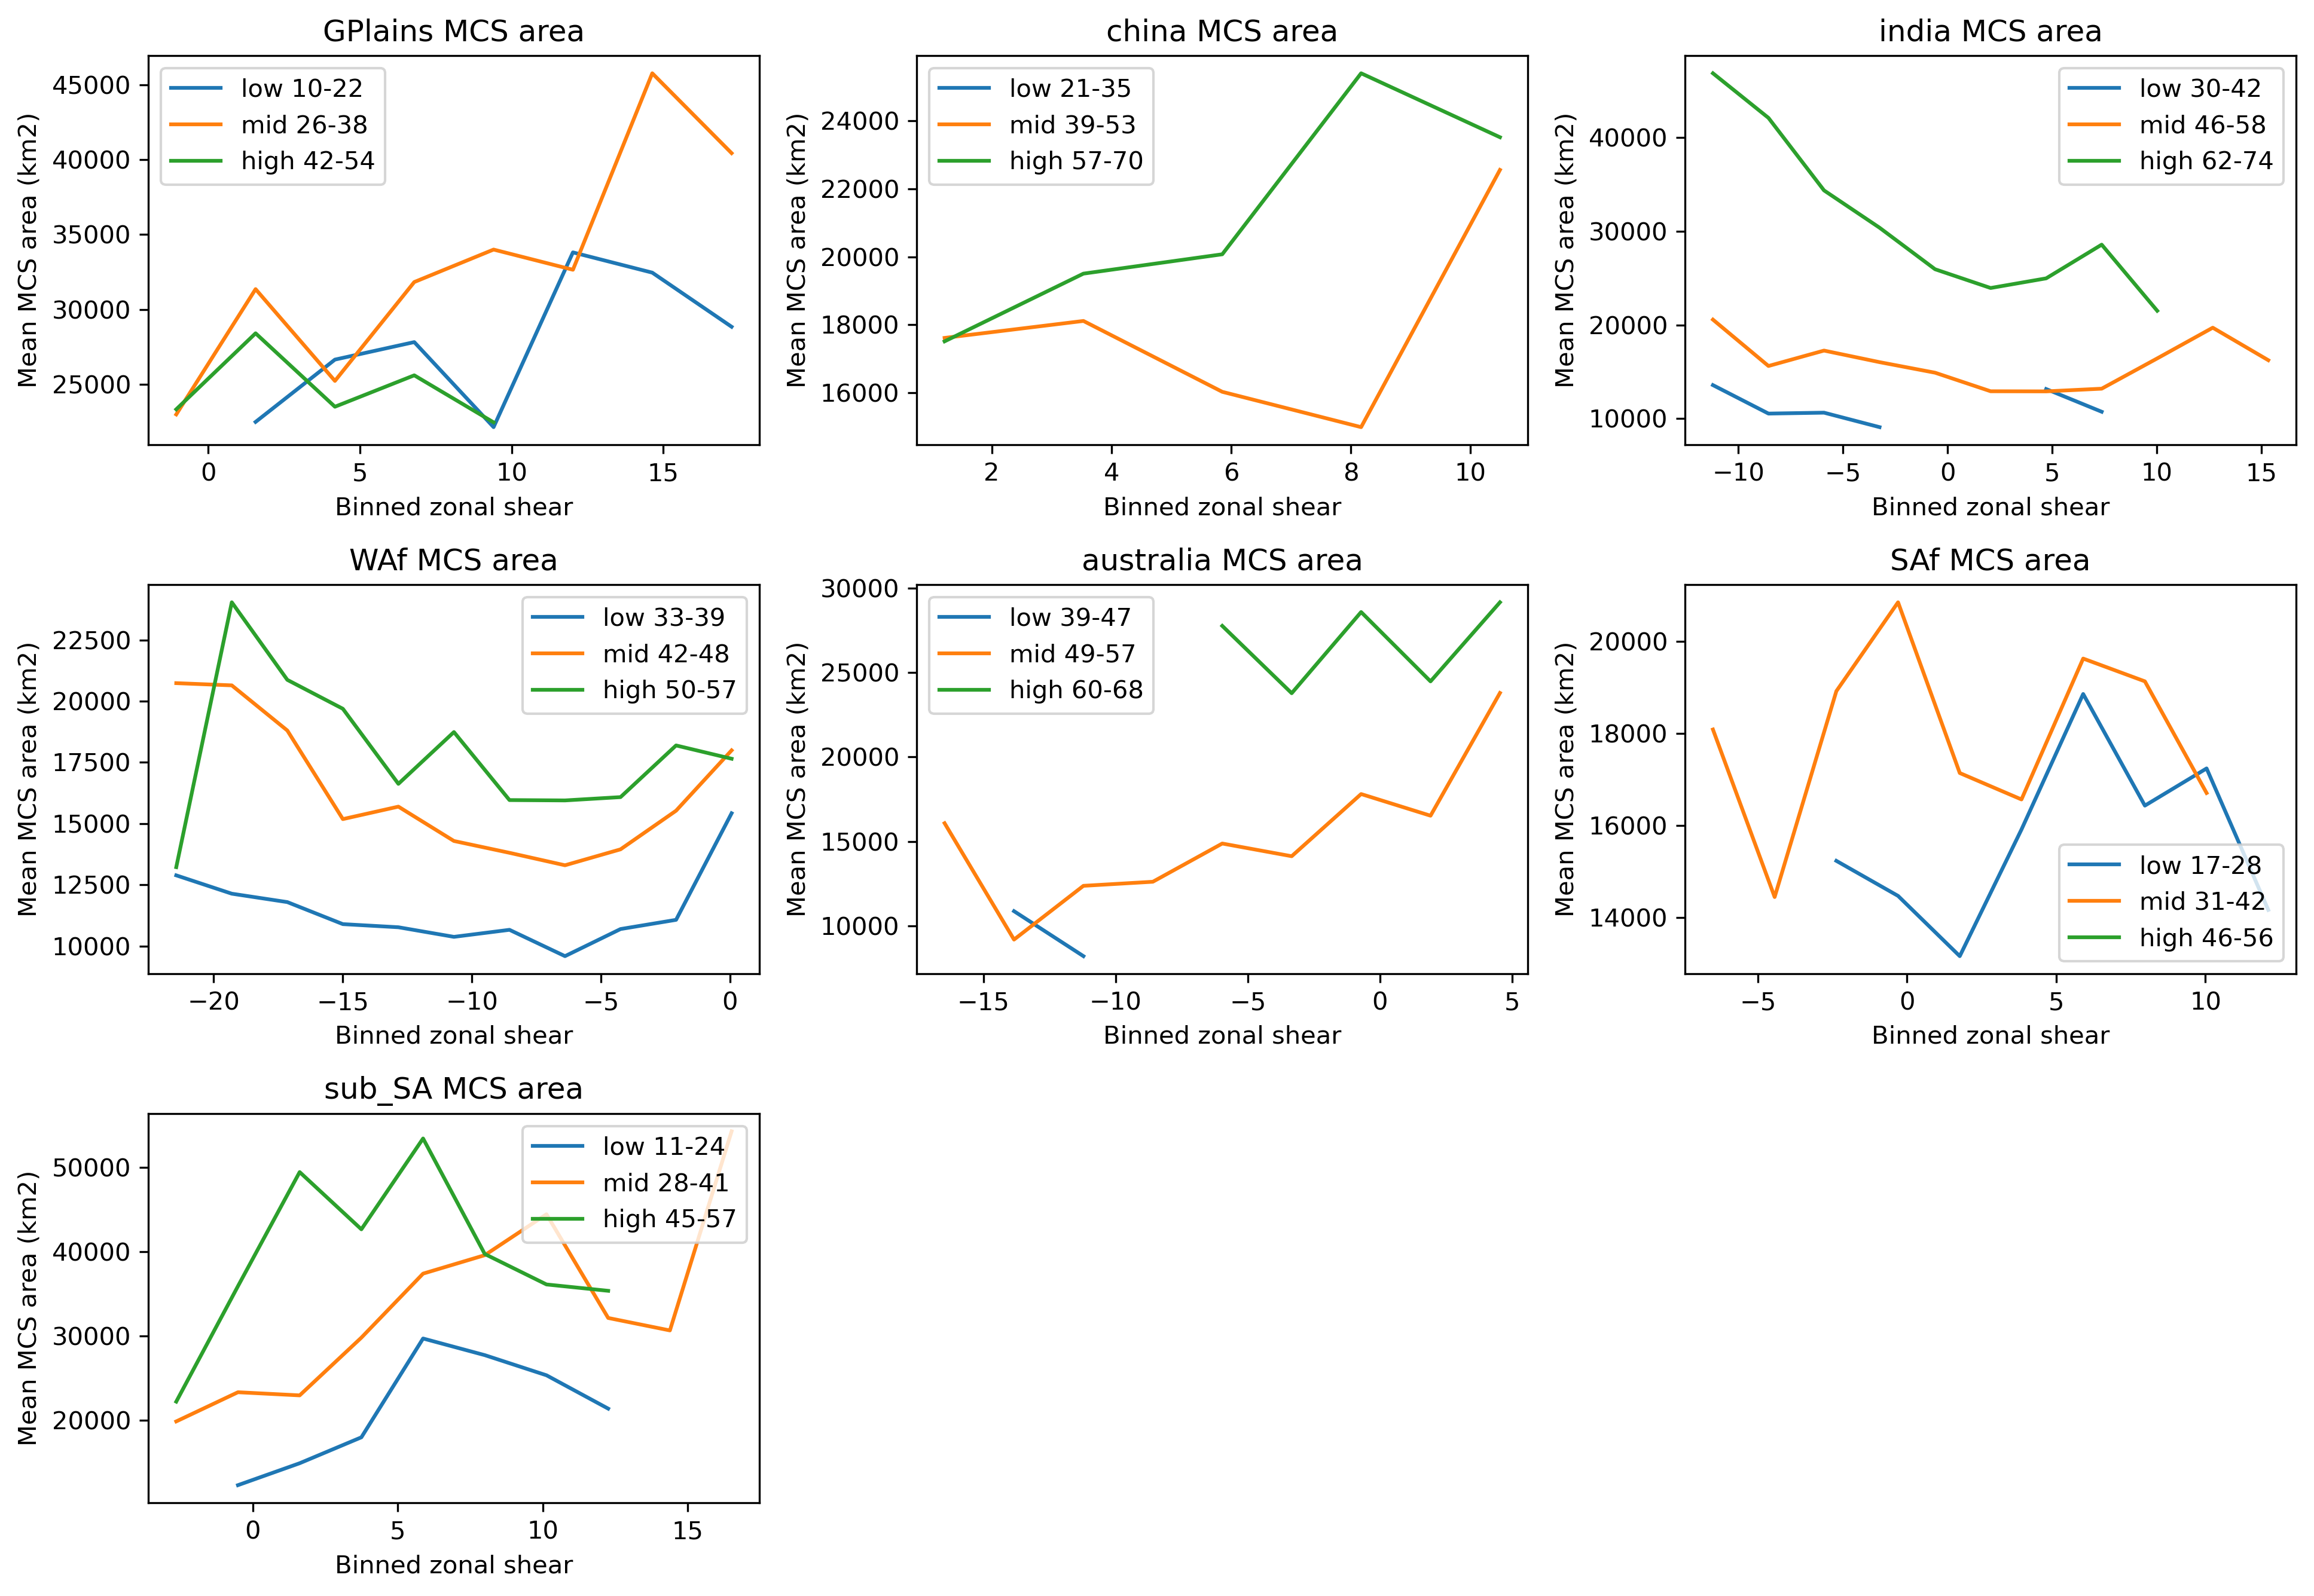

In [48]:
f= plt.figure(figsize=(13,9), dpi=300)
for ids, regs in enumerate(MREGIONS.keys()):
    ax = f.add_subplot(3,3,ids+1)
    
    pick = rdics[regs]
    pick = pick[pick['pf_maxrainrate1']>=8]
    sbin = np.linspace(np.nanpercentile(pick['ushear100m_650'],2), np.nanpercentile(pick['ushear100m_650'],99),12)
    
    if regs == 'india':
        start = 30
    else:
        start = np.nanpercentile(pick['tcwv'],2)
    tbin = np.linspace(start, np.nanpercentile(pick['tcwv'],99),12)
    testbins = [sbin,tbin]
    func1 = lambda y: np.mean(y) #np.percentile(y,95, interpolation='nearest') #np.percentile(y, 95)
    func2 = lambda y: np.sum(np.isfinite(y))
    func3 = lambda y: np.sum(y>1)

    xxu2 = pick['ushear100m_650'].values.astype(np.float64)
    xxtc = pick['tcwv'].values
    #xxtc = pick['q925'].values*1000
    xxch = pick['pf_area1'].values
    
    #ipdb.set_trace()
    
    ret = binned_statistic_2d(xxu2, xxtc, xxch, statistic=func1, bins=testbins)
    count = binned_statistic_2d(xxu2, xxtc, xxch, statistic=func2, bins=testbins)
    # thresh = binned_statistic_2d(xxu2, xxtc, xxch, statistic=func3, bins=testbins)

    dd=ret.statistic.T
    valid = count.statistic.T
    dd[valid<10] = np.nan
    dd = np.array(dd).astype(float)
    

    
    for pp in [(dd[0:4], 'low', str(int(tbin[0]))+'-'+str(int(tbin[3]))), (dd[4:8], 'mid', str(int(tbin[4]))+'-'+str(int(tbin[7]))), (dd[8:12], 'high', str(int(tbin[8]))+'-'+str(int(tbin[11])))]:
        pp1 = pp[0]
        pp2 = pp[1]
        
        pplot = np.nanmean(pp1, axis=0)
        nsum = np.sum(np.isfinite(pp1), axis=0)
    
        pplot[nsum<2] = np.nan
        plt.plot(testbins[0][0:-1], pplot, label=pp2+' '+pp[2])
        plt.title(regs+' IQR ='+str(np.round(np.nanpercentile(xxch,75)-np.nanpercentile(xxch,25),2))+'K')
      
        plt.title(regs+' MCS area')
        plt.xlabel('Binned zonal shear')
        plt.ylabel('Mean MCS area (km2)')
        ax.legend()
plt.tight_layout()

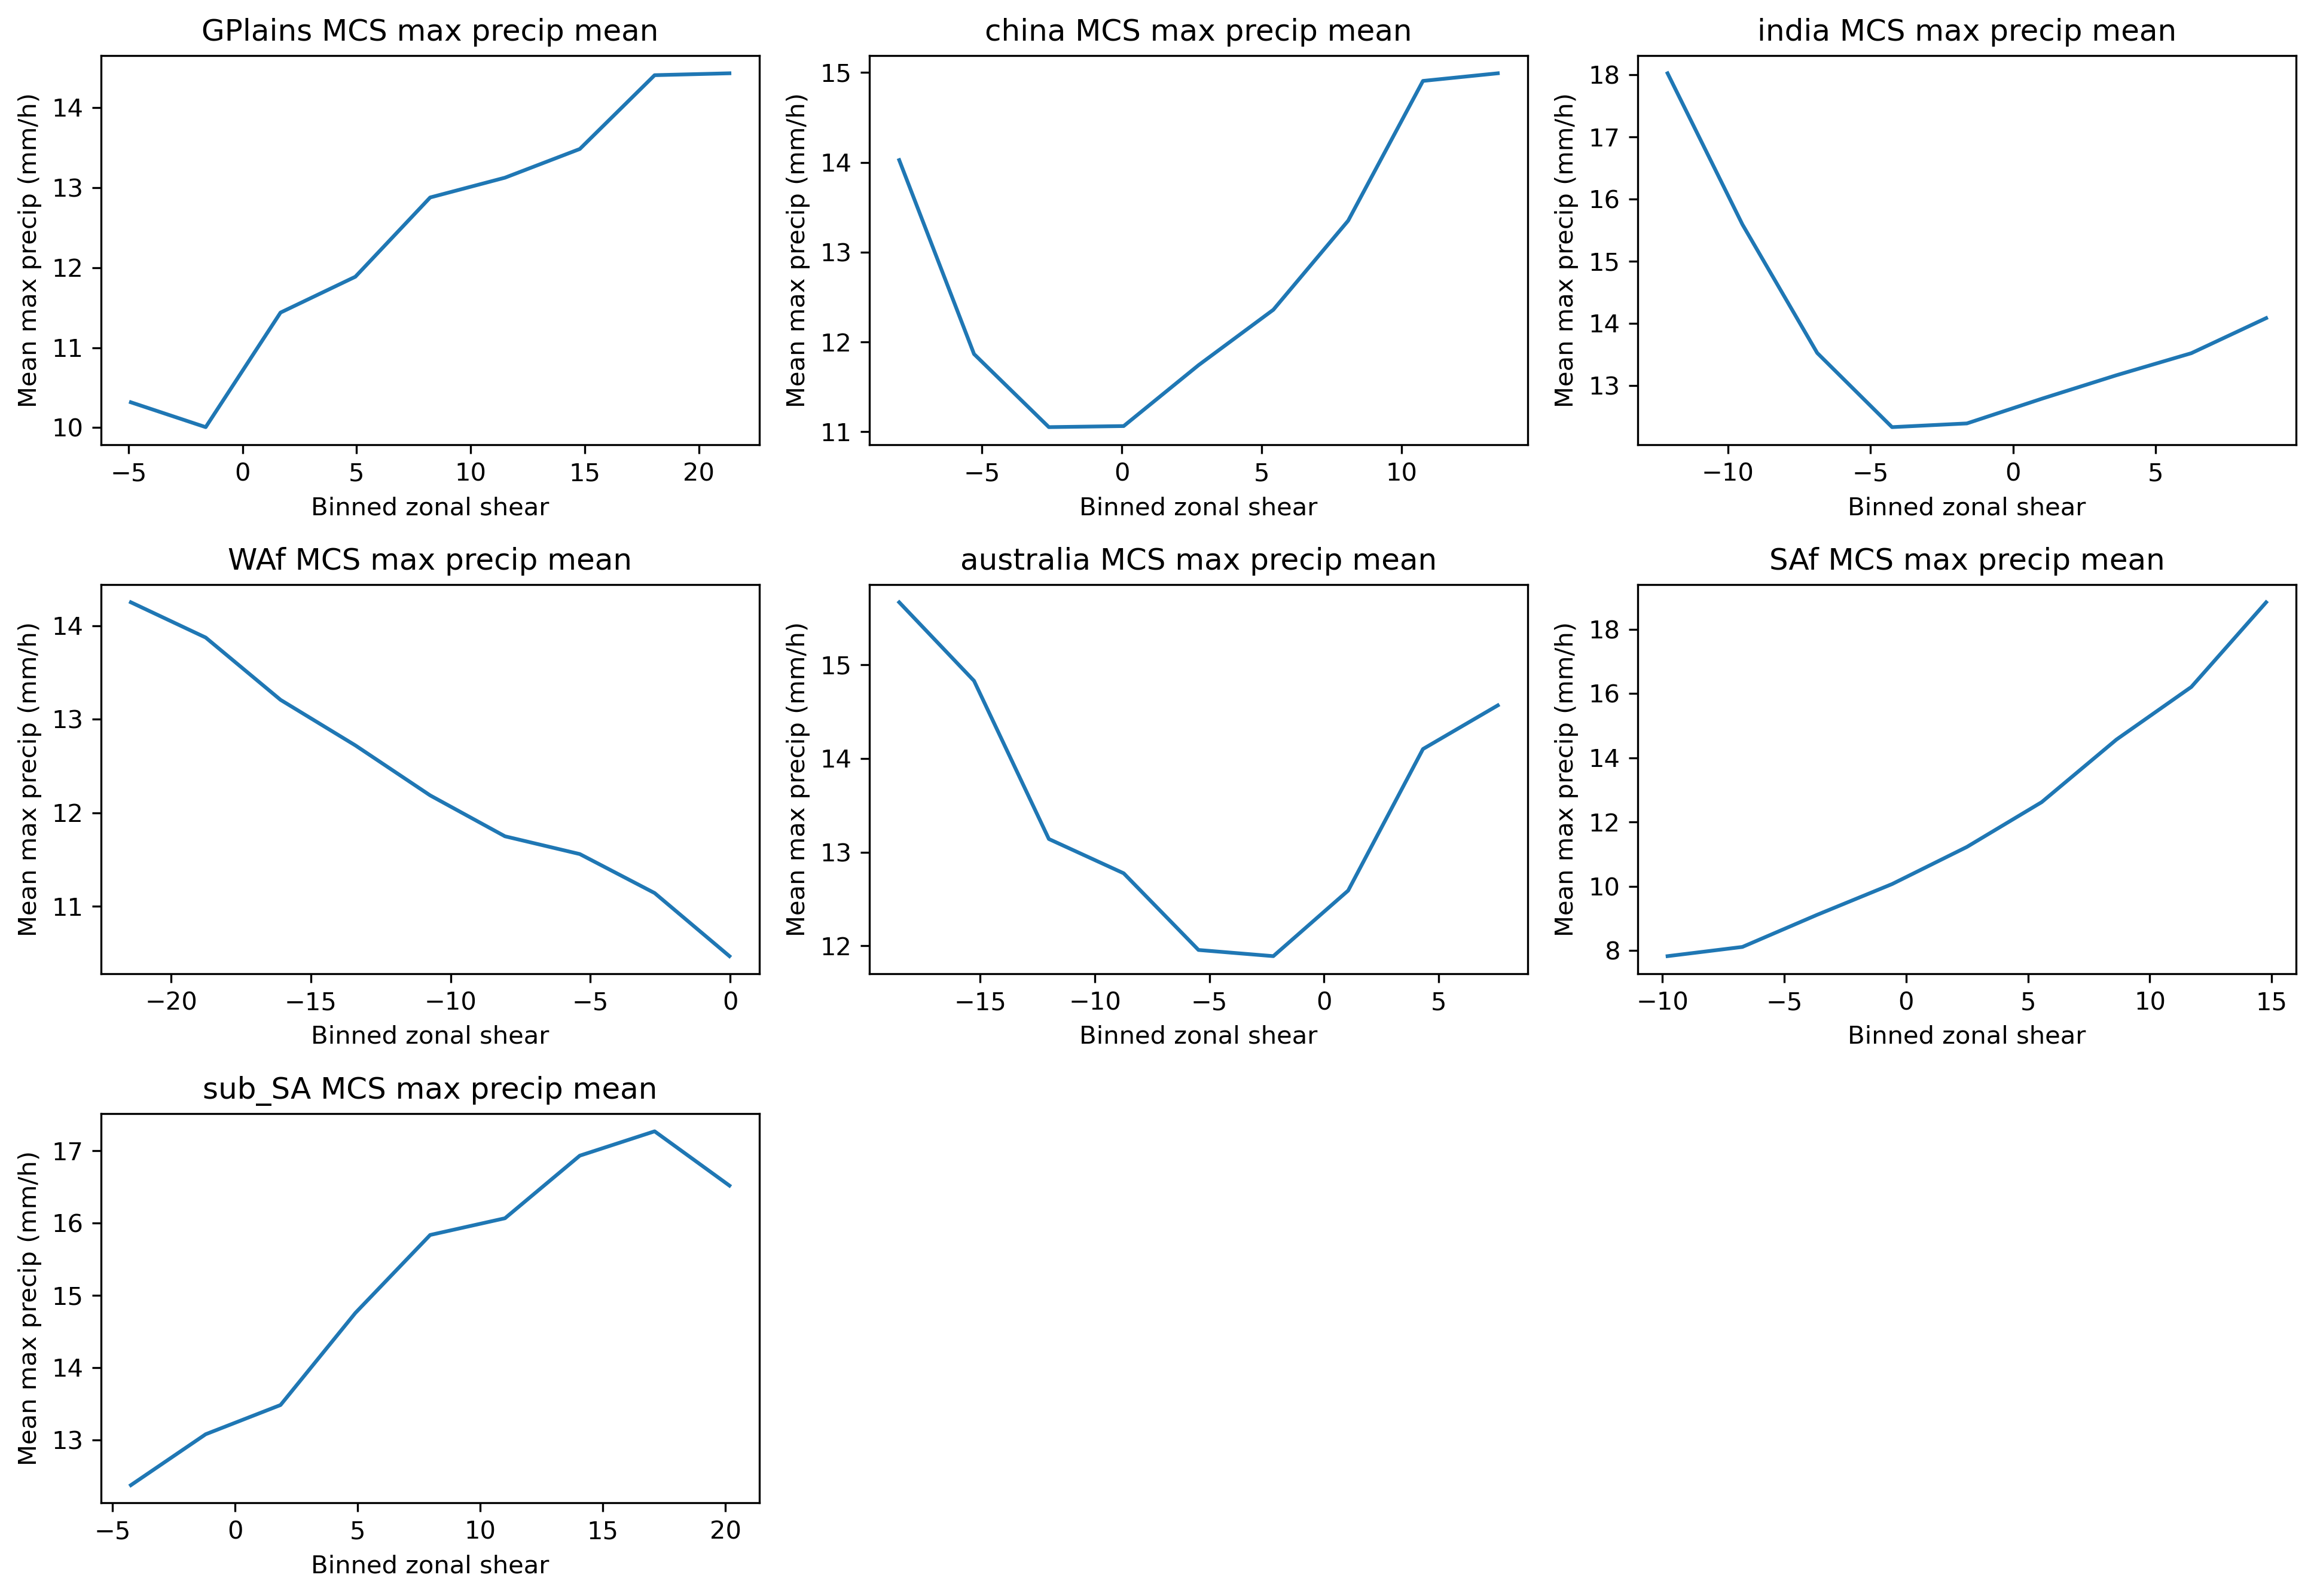

In [16]:
f= plt.figure(figsize=(13,9), dpi=300)
for ids, regs in enumerate(MREGIONS.keys()):
    ax = f.add_subplot(3,3,ids+1)
    
    pick = snapdics[regs]
    pick = pick[pick['precipitation_max']>=2]
#     tbin = np.linspace(5,25,15)
#     #tbin = np.linspace(10,65,15)
#     sbin = np.linspace(-20,15,15)
    sbin = np.linspace(np.nanpercentile(pick['ushear100m_650'],1), np.nanpercentile(pick['ushear100m_650'],99),10)
    tbin = np.linspace(np.nanpercentile(pick['q925']*1000,1), np.nanpercentile(pick['q925']*1000,99),15)
    #tbin = np.linspace(np.nanpercentile(pick['tcwv'],1), np.nanpercentile(pick['tcwv'],98),10)
    #ipdb.set_trace()
    testbins = [sbin,tbin]
    func1 = lambda y: np.mean(y) #np.percentile(y,95, interpolation='nearest') #np.percentile(y, 95)
    func2 = lambda y: np.sum(np.isfinite(y))
    func3 = lambda y: np.sum(y>1)

    xxu2 = pick['ushear100m_650'].values.astype(np.float64)
    #xxtc = pick['tcwv'].values
    xxtc = pick['q925'].values*1000
    xxch = pick['precipitation_max'].values
    
    #ipdb.set_trace()
    
    ret = binned_statistic_2d(xxu2, xxtc, xxch, statistic=func1, bins=testbins)
    count = binned_statistic_2d(xxu2, xxtc, xxch, statistic=func2, bins=testbins)
    # thresh = binned_statistic_2d(xxu2, xxtc, xxch, statistic=func3, bins=testbins)

    dd=ret.statistic.T
    valid = count.statistic.T
    dd[valid<10] = np.nan
    dd = np.array(dd).astype(float)
    
    pplot = np.nanmean(dd, axis=0)

    plt.plot(testbins[0][0:-1], pplot)
    plt.title(regs+' IQR ='+str(np.round(np.nanpercentile(xxch,75)-np.nanpercentile(xxch,25),2))+'K')
    plt.colorbar(mp)
    plt.title(regs+' MCS max precip mean')
    plt.xlabel('Binned zonal shear')
    plt.ylabel('Mean max precip (mm/h)')
plt.tight_layout()